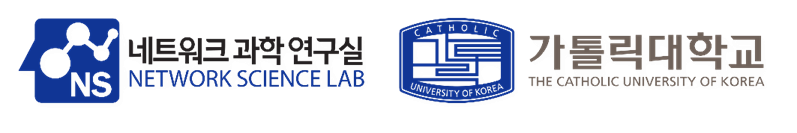

# Week 9: Explainability, Generalizability and Robustness of GNNs

A GNN that reaches a high test accuracy can still be untrustworthy. Let's studies three questions about a trained GNN:
* Explainability: which part of the graph made the model decide?
* Generalizability: does the model still work when the test graphs come from a different distribution?
* Robustness: can a few perturbed edges, features or labels change its predictions?

| Lecture part | Methods / experiments |
|:--|:--|
| Explainability | BA-Shapes, the computation graph of a node, how to score an explanation |
| | Gradient saliency, GNNExplainer |
| | PGExplainer |
| | SubgraphX: Shapley values + Monte-Carlo tree search on BA-2Motifs |
| Generalizability | Spurious-Motif: ID vs. OOD, shortcut learning, size shift |
| | GraphCL and attribute-masking pre-training |
| | G-Mixup: graphons |
| | EERM |
| | DIR |
| Robustness | How perturbations propagate. Random noise on edges, features and labels |
| | Adversarial attacks: targeted attack, DICE, Metattack |
| | Defences: GNNGuard, Pro-GNN, GRAND |
| | NRGNN for noisy labels |
| | Certified robustness of a linear GNN |

# 0. Setup

[**Download the dataset from Dropbox**](https://www.dropbox.com/scl/fo/7i2npwq7ey4zdkyy6cafw/ACARu91UUvy24fxHeGJgrTo?rlkey=jv94en1vp3mrgq0ytmbyyfycn&st=k2c5ftyq&dl=0)

In [1]:
INSTALL_DEPENDENCIES = False

if INSTALL_DEPENDENCIES:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch-geometric", "networkx"])

In [2]:
import math, time, random, copy, warnings, contextlib, io
warnings.filterwarnings("ignore")
from collections import Counter
from types import SimpleNamespace
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx                     
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid, TUDataset, BA2MotifDataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)
ROOT = "./data"
COLORS = {'Grad': '#9a9a9a', 'GNNExplainer': '#2a78d6', 'PGExplainer': '#eb6834', 'SubgraphX': '#1baf7a',
          'random': '#cfcfcf', 'ERM': '#9a9a9a', 'DIR': '#1baf7a', 'GCN': '#2a78d6', 'GNNGuard': '#eb6834',
          'Pro-GNN': '#4a3aa7', 'GRAND': '#1baf7a', 'NRGNN': '#e34948', 'MLP': '#cfcfcf'}

Device: cuda


## 0.1. Message passing on an edge list

A graph is stored as `edge_index` of shape $[2, E]$: column $e$ is a message $j \to i$ from the source $j$ = `edge_index[0, e]` to the target $i$ = `edge_index[1, e]`. An undirected graph stores both directions. `scatter_sum` and `scatter_max` aggregate the values of the edges (or nodes) that share the same index.

In [3]:
def degree(index, N):
    """Number of entries per node; with index = edge_index[1] this is the in-degree."""
    return torch.zeros(N, device=index.device).index_add_(0, index, torch.ones(index.numel(), device=index.device))

def scatter_sum(values, index, N):
    """out[i] = Σ_{e : index[e] = i} values[e]."""
    out = torch.zeros((N,) + values.shape[1:], device=values.device, dtype=values.dtype)
    return out.index_add_(0, index, values)

def scatter_max(values, index, N):
    """out[i] = max_{e : index[e] = i} values[e]  (-inf if node i has no entry)."""
    out = torch.full((N,) + values.shape[1:], -float('inf'), device=values.device, dtype=values.dtype)
    idx = index.view(-1, *([1] * (values.dim() - 1))).expand_as(values)
    return out.scatter_reduce(0, idx, values, reduce='amax')

def undirected_ids(edge_index, N):
    """Id of the undirected edge {i, j} of every directed edge (both directions get the same id), number of ids."""
    key = torch.minimum(edge_index[0], edge_index[1]) * N + torch.maximum(edge_index[0], edge_index[1])
    uniq, inv = torch.unique(key, return_inverse=True)
    return inv, uniq.numel()

def auc(pos, neg):
    """Area under the ROC curve = P(score of a random positive > score of a random negative); ties count 1/2."""
    scores = torch.cat([pos, neg]).double()
    order = scores.argsort()
    ranks = torch.empty_like(scores)
    ranks[order] = torch.arange(1, scores.numel() + 1, device=scores.device, dtype=scores.dtype)
    uniq, inv, counts = torch.unique(scores, return_inverse=True, return_counts=True)
    ranks = (torch.zeros_like(uniq).index_add_(0, inv, ranks) / counts)[inv]      # average rank of tied scores
    return ((ranks[:pos.numel()].sum() - pos.numel() * (pos.numel() + 1) / 2) / (pos.numel() * neg.numel())).item()

# Part I. Explainability

A linear model or a decision tree explains itself: a weight or a split tells how a feature drives the prediction. A GNN mixes node features along many paths, so we need explainers. For one prediction (an instance-level, post-hoc explanation), an explainer returns the edges (and node features) that mattered most. We study three model-agnostic explainers:

| Explainer | What it learns |
|:--|:--|
| Gradient saliency | $\vert\partial\,\text{logit} / \partial\,\text{edge}\vert$ at the input graph | 
| GNNExplainer | a soft edge mask $\sigma(M)$, optimised separately for every prediction |
| PGExplainer | an MLP that outputs the mask of every edge, shared by all predictions |
| SubgraphX | the connected subgraph with the largest Shapley value, found by tree search |

# 1. BA-Shapes: a node classification task with a known answer

**BA-Shapes** (Ying et al., 2019): a Barabási–Albert graph with 300 nodes (every new node links to $m = 5$ existing nodes, chosen with probability proportional to their degree), 80 five-node houses attached to random base nodes, and $0.1N = 70$ random edges. A node's label is its role: 0 = base, 1 = upper corner of a house, 2 = lower corner, 3 = roof. All nodes have the same constant features, so only the structure carries information. For a house node, the ground-truth explanation is the 6 edges of its house.

In [4]:
def ba_edges(n, m, rng):
    """Barabási–Albert graph: start from a star on m+1 nodes; every new node links to m distinct existing nodes,
    each chosen with probability proportional to its degree (`repeated` holds every node once per incident edge)."""
    edges = [(0, i) for i in range(1, m + 1)]
    repeated = [0] * m + list(range(1, m + 1))
    for v in range(m + 1, n):
        targets = set()
        while len(targets) < m:
            targets.add(repeated[rng.integers(len(repeated))])
        for t in targets:
            edges.append((v, t))
            repeated += [v, t]
    return edges

def house(s):
    """House on nodes s..s+4: square s, s+1, s+2, s+3 and roof s+4 on top of s, s+1. Roles: 1 upper, 2 lower, 3 roof."""
    return [(s, s + 1), (s + 1, s + 2), (s + 2, s + 3), (s + 3, s), (s + 4, s), (s + 4, s + 1)], [1, 1, 2, 2, 3]

def ba_shapes(n_base=300, m=5, n_houses=80, n_random=70, seed=0):
    rng = np.random.default_rng(seed)
    edges, labels, motif_edges = ba_edges(n_base, m, rng), [0] * n_base, []
    for h in range(n_houses):
        s = n_base + 5 * h
        e, roles = house(s)
        edges += e; motif_edges += e; labels += roles
        edges.append((s, int(rng.integers(n_base))))             # attach the house to a random base node
    N = len(labels)
    existing, added = {tuple(sorted(e)) for e in edges}, 0
    while added < n_random:                                      # random edges (noise)
        u, v = map(int, rng.integers(N, size=2))
        if u != v and (min(u, v), max(u, v)) not in existing:
            existing.add((min(u, v), max(u, v))); edges.append((u, v)); added += 1
    ei = torch.tensor(edges).t()
    ei = torch.cat([ei, ei.flip(0)], dim=1)                      # both directions
    gt = {tuple(sorted(e)) for e in motif_edges}
    gt_edge = torch.tensor([tuple(sorted(e)) in gt for e in ei.t().tolist()])   # ground truth: house edges
    return ei.to(device), torch.tensor(labels, device=device), gt_edge.to(device)

edge_index, y, gt_edge = ba_shapes()
N = y.numel()
x = torch.ones(N, 10, device=device)                             # constant features, as in the GNNExplainer code
deg = degree(edge_index[1], N)
print(f'Nodes: {N} | undirected edges: {edge_index.size(1) // 2} (house edges: {int(gt_edge.sum()) // 2})')
print('Nodes per role (0 base, 1 upper, 2 lower, 3 roof):', torch.bincount(y).tolist())
print(f'Mean degree: base {deg[y == 0].mean():.1f} (max {deg.max():.0f}) | house nodes {deg[y > 0].mean():.1f}')

Nodes: 700 | undirected edges: 2105 (house edges: 480)
Nodes per role (0 base, 1 upper, 2 lower, 3 roof): [300, 160, 160, 80]
Mean degree: base 10.3 (max 55) | house nodes 2.8


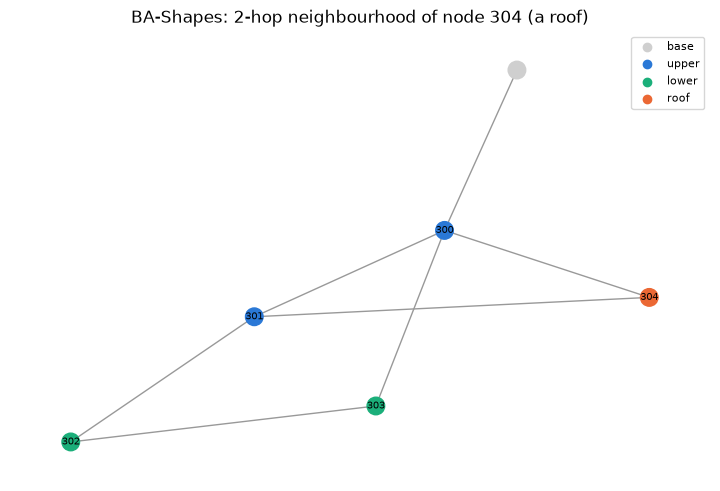

In [5]:
# The 2-hop neighbourhood of one house (roof node 304): roles as colours
role_colors = ['#cfcfcf', '#2a78d6', '#1baf7a', '#eb6834']
v = 304
near = set(edge_index[0, edge_index[1] == v].tolist()) | {v}
near |= set(edge_index[0, torch.isin(edge_index[1], torch.tensor(sorted(near), device=device))].tolist())
G = nx.Graph([(a, b) for a, b in edge_index.t().tolist() if a in near and b in near])
plt.figure(figsize=(7, 4.5))
pos = nx.spring_layout(G, seed=1)
nx.draw(G, pos, node_size=160, node_color=[role_colors[y[n]] for n in G], edge_color='#999999',
        labels={n: n for n in G if n >= 300}, font_size=7)
for r, name in enumerate(['base', 'upper', 'lower', 'roof']):
    plt.scatter([], [], color=role_colors[r], label=name)
plt.legend(fontsize=8); plt.title(f'BA-Shapes: 2-hop neighbourhood of node {v} (a roof)'); plt.show()

## 1.1. The GNN to explain

As in the GNNExplainer code, the GNN aggregates with a **sum**: $h_i' = W\big(h_i + \sum_{j\in\mathcal N(i)} m_{ji}\,h_j\big) + b$, followed by batch normalisation and ReLU. Three layers are concatenated and fed to a linear classifier. The factor $m_{ji}$ multiplies the message $j\to i$: it is 1 for the normal forward pass, and the explainers will replace it by a mask in $[0, 1]$.

Why a sum? With constant features, a GCN with $1/\sqrt{d_id_j}$ weights reads the structure through the degrees of the base nodes. A house node is then not classified from its house alone, and the ground-truth explanation would be wrong for that model.

In [6]:
class SumConv(nn.Module):
    """h_i' = W (h_i + Σ_{j ∈ N(i)} m_ji h_j) + b   (m = 1, or an explainer's mask on the messages)."""
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin = nn.Linear(in_dim, out_dim)

    def forward(self, x, edge_index, edge_mask=None):
        src, dst = edge_index
        msg = x[src] if edge_mask is None else edge_mask[:, None] * x[src]
        return self.lin(x + scatter_sum(msg, dst, x.size(0)))

class NodeGNN(nn.Module):
    """3 SumConv layers (BN + ReLU); the concatenated layer outputs feed a linear classifier."""
    def __init__(self, in_dim, hidden, out_dim, num_layers=3):
        super().__init__()
        self.convs = nn.ModuleList([SumConv(in_dim if l == 0 else hidden, hidden) for l in range(num_layers)])
        self.bns = nn.ModuleList([nn.BatchNorm1d(hidden) for _ in range(num_layers)])
        self.lin = nn.Linear(num_layers * hidden, out_dim)

    def embed(self, x, edge_index, edge_mask=None):
        hs = []
        for conv, bn in zip(self.convs, self.bns):
            x = F.relu(bn(conv(x, edge_index, edge_mask)))
            hs.append(x)
        return torch.cat(hs, dim=-1)

    def forward(self, x, edge_index, edge_mask=None):
        return self.lin(self.embed(x, edge_index, edge_mask))

perm = torch.randperm(N, generator=torch.Generator().manual_seed(0)).to(device)
train_idx, test_idx = perm[:int(0.8 * N)], perm[int(0.8 * N):]
set_seed(0)
model = NodeGNN(10, 64, 4).to(device)
opt = torch.optim.Adam(model.parameters(), lr=0.005)
for epoch in range(2000):
    model.train(); opt.zero_grad()
    F.cross_entropy(model(x, edge_index)[train_idx], y[train_idx]).backward(); opt.step()
model.eval()
for p in model.parameters():
    p.requires_grad_(False)                                      # the explainers never change the model
with torch.no_grad():
    pred = model(x, edge_index).argmax(1)
print(f'Train acc: {(pred[train_idx] == y[train_idx]).float().mean():.3f} | Test acc: {(pred[test_idx] == y[test_idx]).float().mean():.3f}')

Train acc: 0.995 | Test acc: 0.971


# 2. The computation graph and how to score an explanation

Computation graph. An $L$-layer GNN computes $h_v$ from the messages that can reach $v$ in $L$ steps. A message $j \to i$ sent at layer $l$ reaches $v$ only if $\mathrm{dist}(i, v) \le L - l$, so $G_c(v)$ is the set of directed messages $j\to i$ with $\mathrm{dist}(i, v) \le L-1.

To explain many nodes at once we stack one copy of every computation graph into a single disconnected graph. Each copy keeps the nodes within $L+1$ hops, so every degree the GNN uses is the same as in the full graph (this matters for degree-normalised GNNs). Messages outside $G_c(v)$ keep the factor 1. The predictions on the stacked copies must be identical to the predictions on the full graph.

In [7]:
def hop_distance(v, edge_index, N, max_hops):
    """Number of hops from every node to v (max_hops + 1 if farther)."""
    dist = torch.full((N,), max_hops + 1, dtype=torch.long, device=edge_index.device)
    dist[v] = 0
    frontier = torch.zeros(N, dtype=torch.bool, device=edge_index.device)
    frontier[v] = True
    for h in range(1, max_hops + 1):
        nxt = torch.zeros_like(frontier)
        nxt[edge_index[0][frontier[edge_index[1]]]] = True
        nxt &= dist > h
        dist[nxt] = h
        frontier = nxt
    return dist

def computation_graphs(targets, x, edge_index, N, num_layers):
    """Disjoint union of one copy of the computation graph of every target node.
    expl[e] = True for the messages of G_c(v) (the ones an explanation can keep or drop)."""
    xs, eis, centers, orig_nodes, orig_edges, owner, expl = [], [], [], [], [], [], []
    offset = 0
    for g, v in enumerate(targets.tolist()):
        dist = hop_distance(v, edge_index, N, num_layers + 1)
        keep = dist <= num_layers + 1
        subset = keep.nonzero().view(-1)
        emask = keep[edge_index[0]] & keep[edge_index[1]]
        relabel = torch.full((N,), -1, dtype=torch.long, device=device)
        relabel[subset] = torch.arange(subset.numel(), device=device)
        sub = relabel[edge_index[:, emask]]
        xs.append(x[subset]); eis.append(sub + offset); centers.append(relabel[v].view(1) + offset)
        orig_nodes.append(subset); orig_edges.append(emask.nonzero().view(-1))
        owner.append(torch.full((sub.size(1),), g, device=device))
        # ★ KEY: message j -> i belongs to G_c(v) iff dist(i, v) <= L - 1.
        expl.append(dist[subset][sub[1]] <= num_layers - 1)
        offset += subset.numel()
    return dict(x=torch.cat(xs), edge_index=torch.cat(eis, 1), targets=torch.cat(centers), num=len(targets),
                orig_nodes=torch.cat(orig_nodes), orig_edges=torch.cat(orig_edges), owner=torch.cat(owner),
                expl=torch.cat(expl), N=offset)

house_nodes = torch.arange(300, N, device=device)          # the 400 nodes we explain
cg = computation_graphs(house_nodes, x, edge_index, N, num_layers=3)
with torch.no_grad():
    out = model(cg['x'], cg['edge_index'])[cg['targets']]
target_class = out.argmax(1)                                # we explain the model's prediction
sizes = torch.bincount(cg['owner'][cg['expl']], minlength=cg['num']).float()
print(f"{cg['num']} computation graphs, {cg['N']} nodes and {cg['edge_index'].size(1)} messages in total")
print(f'Messages per computation graph: mean {sizes.mean():.0f}, min {sizes.min():.0f}, max {sizes.max():.0f}')
print(f"Same predictions as on the full graph: {(target_class == pred[house_nodes]).float().mean():.3f} "
      f"(max |logit difference| = {(out - model(x, edge_index)[house_nodes]).abs().max():.1e})")

400 computation graphs, 71580 nodes and 565912 messages in total
Messages per computation graph: mean 74, min 13, max 874
Same predictions as on the full graph: 1.000 (max |logit difference| = 1.7e-05)


Scoring an explanation. An explainer gives every message of $G_c(v)$ an importance. As in the GNNExplainer and PGExplainer papers, we treat explanation as edge classification: the ground truth is "this message runs along a house edge", the importance is the score, and we report the AUC. We give it pooled over all 400 explanations (as in the papers) and averaged per role.

Two sanity checks come first:
* A random explanation must score 0.5 (we score every directed message once, so a random score is not favoured).
* The empty explanation (all messages of $G_c(v)$ removed): if the model still makes the same prediction without any message, the prediction needs no evidence from the graph. An explainer can then return an empty explanation that is still perfectly faithful.

In [8]:
roles = y[house_nodes]
gt_msg = gt_edge[cg['orig_edges']]                       # ground truth of every message of the stacked graph

def explanation_auc(score, cg=cg, gt=gt_msg, roles=roles):
    """Pooled AUC over all explanations and mean AUC of the explanations of every role (1, 2, 3)."""
    e = cg['expl']
    pooled = auc(score[e & gt], score[e & ~gt])
    per = torch.full((cg['num'],), float('nan'))
    for g in range(cg['num']):
        m = e & (cg['owner'] == g)
        if (m & gt).any() and (m & ~gt).any():
            per[g] = auc(score[m & gt], score[m & ~gt])
    by_role = [float(np.nanmean(per[(roles == r).cpu()].numpy())) for r in (1, 2, 3)]
    return pooled, by_role, per

def report(name, score, seconds=None):
    pooled, by_role, _ = explanation_auc(score)
    t = f' | {seconds:.1f}s' if seconds is not None else ''
    print(f'{name:<14} AUC pooled {pooled:.3f} | upper {by_role[0]:.3f} | lower {by_role[1]:.3f} | roof {by_role[2]:.3f}{t}')
    return pooled, by_role

EXPL_RESULTS = {}
set_seed(0)
EXPL_RESULTS['random'] = report('random', torch.rand(cg['edge_index'].size(1), device=device))

with torch.no_grad():   # empty explanation: drop every message of G_c(v)
    out = model(cg['x'], cg['edge_index'], (~cg['expl']).float())[cg['targets']]
same = out.argmax(1) == target_class
for r, name in [(1, 'upper'), (2, 'lower'), (3, 'roof')]:
    print(f'Empty explanation keeps the prediction of {same[roles == r].float().mean():.0%} of the {name} nodes')

random         AUC pooled 0.491 | upper 0.504 | lower 0.471 | roof 0.470
Empty explanation keeps the prediction of 1% of the upper nodes
Empty explanation keeps the prediction of 100% of the lower nodes
Empty explanation keeps the prediction of 6% of the roof nodes


# 3. Gradient saliency and GNNExplainer
## 3.1. Gradient saliency

The simplest explainer: the importance of message $j\to i$ is the absolute gradient of the target logit with respect to its factor $m_{ji}$, at $m = 1$. One backward pass explains all 400 nodes, because the copies are disconnected.

In [9]:
def grad_saliency(model, cg, target_class):
    m = torch.ones(cg['edge_index'].size(1), device=device, requires_grad=True)
    out = model(cg['x'], cg['edge_index'], m)[cg['targets']]
    out.gather(1, target_class[:, None]).sum().backward()      # Σ_v logit_v(ŷ_v): copies do not interact
    return torch.where(cg['expl'], m.grad.abs(), torch.zeros_like(m.grad))

t0 = time.time()
grad_score = grad_saliency(model, cg, target_class)
EXPL_RESULTS['Grad'] = report('Grad', grad_score, time.time() - t0)

Grad           AUC pooled 0.966 | upper 0.960 | lower 0.846 | roof 0.934 | 0.1s


## 3.2. GNNExplainer

Objective. Find the subgraph $G_S \subseteq G_c$ that maximises the mutual information with the prediction, $\max_{G_S} MI(Y, G_S) = H(Y) - H(Y \mid G = G_S)$. The model is fixed, so $H(Y)$ is constant and we minimise the conditional entropy.

Continuous relaxation. A subgraph is a binary mask on the $2^{|E_c|}$ possible edge sets. GNNExplainer learns a real mask $M$ instead and multiplies every message by $\sigma(M_{ji})$ ($A_S = A_c\odot\sigma(M)$). The loss is the cross-entropy of the model's predicted class $\hat y$:

$$\min_M\; -\log P_\Phi\big(Y = \hat y \mid A_c\odot\sigma(M),\, X\big)\;+\;\alpha\sum_{(j,i)}\sigma(M_{ji})\;+\;\beta\,\frac{1}{|E_c|}\sum_{(j,i)} H\big(\sigma(M_{ji})\big),\qquad H(m) = -m\log m-(1-m)\log(1-m).$$

* Size: a norm penalty; for a non-negative mask it is the sum of the mask values. It keeps the explanation small ($\alpha = 0.005$).
* Entropy: it pushes every mask value towards 0 or 1, so the soft mask approximates a real subgraph ($\beta = 1$).
* Feature mask: $X_S = X\odot\sigma(F)$ with one $F$ per explanation. BA-Shapes has constant features, so we switch it off here (it is used on molecules in the assignment).

Batching: Adam updates every parameter independently, so optimising the 400 masks together, with one loss per copy, gives the same result as 400 separate runs.

In [10]:
def mask_regulariser(m, owner, num, size_coef, ent_coef, size_reduce='sum'):
    """size_coef · Σ m (or mean, per explanation) + ent_coef · mean H(m), for every explanation (owner = its id)."""
    ent = -m * torch.log(m + 1e-15) - (1 - m) * torch.log(1 - m + 1e-15)
    count = torch.bincount(owner, minlength=num).clamp(min=1).float()
    size = scatter_sum(m, owner, num)
    if size_reduce == 'mean':
        size = size / count
    return size_coef * size.sum() + ent_coef * (scatter_sum(ent, owner, num) / count).sum()

def gnnexplainer(predict, x, owner, node_owner, num, target_class, explained, epochs=300, lr=0.01,
                 size_coef=0.005, ent_coef=1.0, feat_mask=False, feat_size_coef=1.0, feat_ent_coef=0.1):
    """GNNExplainer for `num` predictions at once. predict(edge_mask, x) returns the logits of the `num` targets;
    owner[e] / node_owner[n] = explanation of message e / node n; explained[e] = message e can be masked."""
    E = owner.numel()
    M = nn.Parameter(0.05 * torch.randn(int(explained.sum()), device=device))
    params = [M]
    if feat_mask:
        Fm = nn.Parameter(0.1 * torch.randn(num, x.size(1), device=device))
        params.append(Fm)
    opt = torch.optim.Adam(params, lr=lr)
    for epoch in range(epochs):
        opt.zero_grad()
        m = torch.sigmoid(M)
        # ★ KEY: A_S = A_c ⊙ σ(M): every message of G_c(v) is scaled by its mask value, the others stay at 1.
        edge_mask = torch.ones(E, device=device).masked_scatter(explained, m)
        xs = x * torch.sigmoid(Fm)[node_owner] if feat_mask else x          # X_S = X ⊙ σ(F)
        logp = F.log_softmax(predict(edge_mask, xs), -1).gather(1, target_class[:, None]).squeeze(1)
        loss = -logp.sum() + mask_regulariser(m, owner[explained], num, size_coef, ent_coef)
        if feat_mask:
            fm = torch.sigmoid(Fm)
            loss = loss + mask_regulariser(fm.reshape(-1), torch.arange(num, device=device).repeat_interleave(x.size(1)),
                                           num, feat_size_coef, feat_ent_coef, size_reduce='mean')
        loss.backward()
        opt.step()
    edge_imp = torch.zeros(E, device=device).masked_scatter(explained, torch.sigmoid(M).detach())
    return edge_imp, (torch.sigmoid(Fm).detach() if feat_mask else None)

predict_nodes = lambda em, xs: model(xs, cg['edge_index'], em)[cg['targets']]
set_seed(0)
t0 = time.time()
gnnexp_score, _ = gnnexplainer(predict_nodes, cg['x'], cg['owner'], None, cg['num'], target_class, cg['expl'])
EXPL_RESULTS['GNNExplainer'] = report('GNNExplainer', gnnexp_score, time.time() - t0)

GNNExplainer   AUC pooled 0.497 | upper 0.738 | lower 0.506 | roof 0.718 | 6.2s


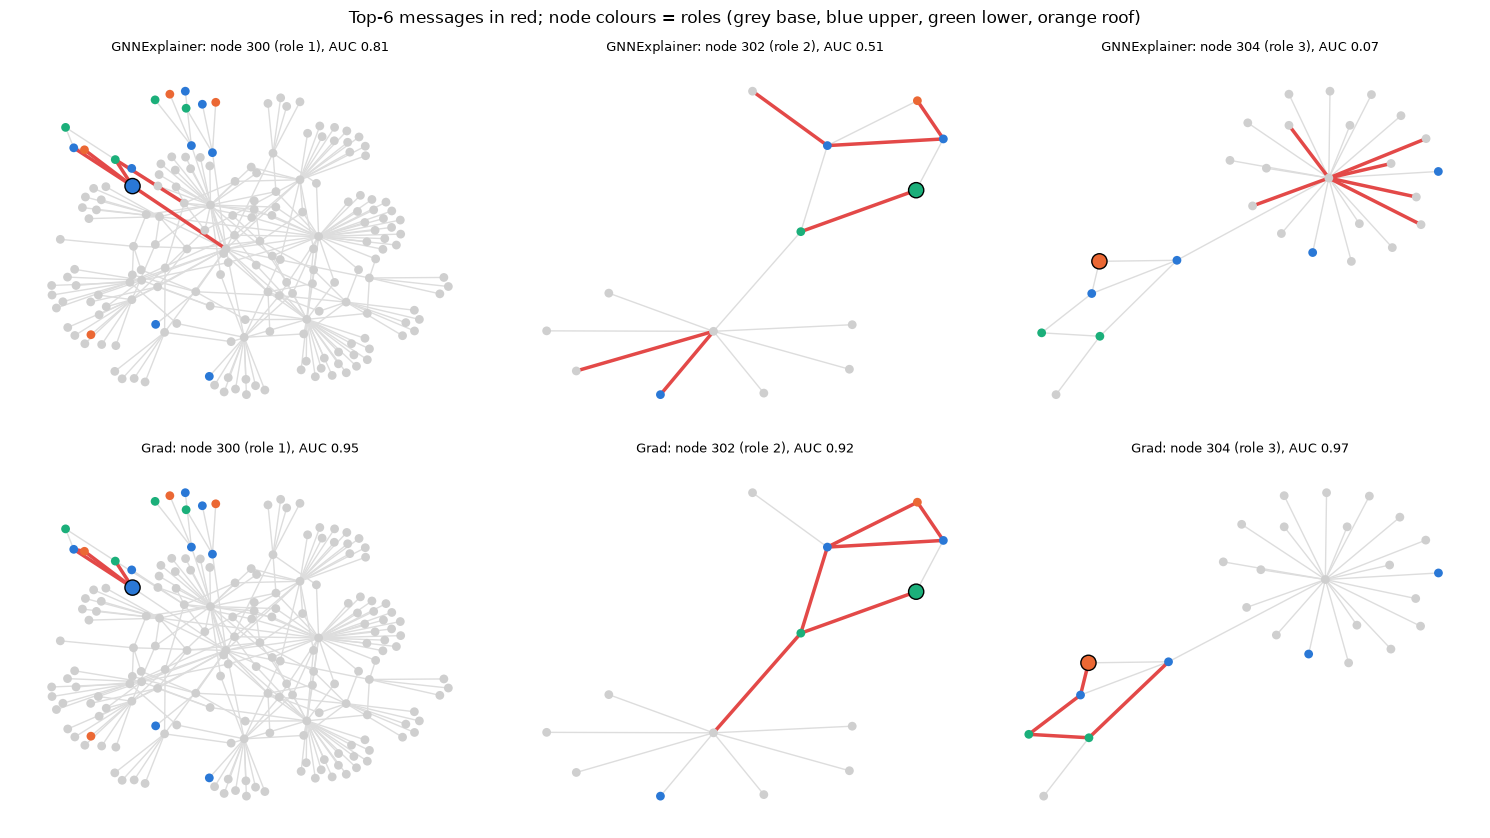

GNNExplainer mask of lower node 302: max 0.036, mean 0.036 -> almost every message is dropped


In [11]:
def draw_explanation(ax, cg, g, score, title, top_k=6):
    """Draw the computation graph of explanation g; the top_k messages (largest scores) are drawn in red."""
    m = cg['expl'] & (cg['owner'] == g)
    idx = m.nonzero().view(-1)
    top = set(idx[score[idx].topk(min(top_k, idx.numel())).indices].tolist())
    on = cg['orig_nodes']
    G = nx.Graph()
    for e in idx.tolist():
        a, b = on[cg['edge_index'][0, e]].item(), on[cg['edge_index'][1, e]].item()
        hot = e in top or (G.has_edge(a, b) and G[a][b]['hot'])
        G.add_edge(a, b, hot=hot, house=bool(gt_msg[e]))
    v = on[cg['targets'][g]].item()
    pos = nx.spring_layout(G, seed=0)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=[e for e in G.edges if not G.edges[e]['hot']], edge_color='#dddddd')
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=[e for e in G.edges if G.edges[e]['hot']], edge_color='#e34948', width=2.5)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[120 if n == v else 40 for n in G],
                           node_color=[role_colors[y[n]] for n in G], edgecolors=['black' if n == v else 'none' for n in G])
    ax.set_title(title, fontsize=9); ax.axis('off')

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for col, v in enumerate([300, 302, 304]):                 # an upper, a lower and a roof node of the first house
    g = v - 300
    for row, (name, s) in enumerate([('GNNExplainer', gnnexp_score), ('Grad', grad_score)]):
        a = explanation_auc(s)[2][g].item()
        draw_explanation(axes[row, col], cg, g, s, f'{name}: node {v} (role {y[v].item()}), AUC {a:.2f}')
plt.suptitle('Top-6 messages in red; node colours = roles (grey base, blue upper, green lower, orange roof)')
plt.tight_layout(); plt.show()

v, g = 302, 2
mv = gnnexp_score[cg['expl'] & (cg['owner'] == g)]
print(f'GNNExplainer mask of lower node {v}: max {mv.max():.3f}, mean {mv.mean():.3f} -> almost every message is dropped')

# 4. PGExplainer

GNNExplainer solves a new optimisation problem for every prediction: it is slow and cannot explain an unseen node without retraining. PGExplainer learns one explanation network for all predictions:

1. Embeddings of the trained GNN: $Z = \mathrm{GNNE}_{\Phi_0}(G_o, X)$ (we use the concatenated layer outputs).
2. For every message $j\to i$ of $G_c(v)$, an MLP predicts a logit $\omega_{ji} = g_\Psi([z_j\,\Vert\, z_i\,\Vert\, z_v])$.
3. Binary concrete sample of the edge, the reparameterised relaxation of $e_{ji}\sim\mathrm{Bern}(\theta_{ji})$:
$$\hat e_{ji} = \sigma\big((\log\epsilon - \log(1-\epsilon) + \omega_{ji})/\tau\big),\qquad \epsilon\sim\mathcal U(0,1).$$
   The temperature goes from $\tau = 5$ to $\tau = 2$ during training.
4. Loss ($K = 1$ Monte-Carlo sample per step): the cross-entropy between the original prediction and the prediction on the sampled graph, plus the size and entropy regularisers ($0.05$ and $1$).

At test time the mask is simply $\sigma(\omega_{ji})$: one forward pass of the MLP (we rank the messages by $\omega_{ji}$, which gives the same order without ties when $\sigma$ saturates). We train $g_\Psi$ on 200 house nodes and explain the 200 other nodes, which it has never seen (inductive setting).

In [12]:
class PGExplainer(nn.Module):
    """Explanation network g_Ψ: an MLP on [z_j || z_i || z_v] that outputs one logit ω_ji per message j -> i."""
    def __init__(self, emb_dim, hidden=64):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(3 * emb_dim, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, z, cg):
        src, dst = cg['edge_index'][:, cg['expl']]
        center = z[cg['targets']][cg['owner'][cg['expl']]]
        return self.mlp(torch.cat([z[src], z[dst], center], -1)).squeeze(-1)

def binary_concrete(logits, tau, bias=0.01):
    """ê = σ((log ε - log(1 - ε) + ω) / τ), ε ~ U(bias, 1 - bias) (PyG keeps ε away from 0 and 1)."""
    eps = (1 - 2 * bias) * torch.rand_like(logits) + bias
    return torch.sigmoid((eps.log() - (1 - eps).log() + logits) / tau)

def train_pgexplainer(explainer, model, cg, z, target_class, epochs=300, lr=0.003, size_coef=0.05, ent_coef=1.0,
                      t0=5.0, t1=2.0):
    opt = torch.optim.Adam(explainer.parameters(), lr=lr)
    E, expl = cg['edge_index'].size(1), cg['expl']
    for epoch in range(epochs):
        tau = t0 * (t1 / t0) ** (epoch / epochs)                 # temperature schedule 5 -> 2
        opt.zero_grad()
        # ★ KEY: the mask of every message comes from the SAME network g_Ψ (collective explanation).
        m = binary_concrete(explainer(z, cg), tau)
        edge_mask = torch.ones(E, device=device).masked_scatter(expl, m)
        logp = F.log_softmax(model(cg['x'], cg['edge_index'], edge_mask)[cg['targets']], -1)
        loss = -logp.gather(1, target_class[:, None]).sum() + mask_regulariser(m, cg['owner'][expl], cg['num'], size_coef, ent_coef)
        loss.backward()
        opt.step()
    return explainer

@torch.no_grad()
def pg_explain(explainer, cg, z):
    """Importance of every message of G_c(v) = its logit ω; the mask is σ(ω), but ranking by ω avoids ties when σ
    saturates at 1 (messages outside G_c(v) get -inf)."""
    return torch.full((cg['edge_index'].size(1),), -float('inf'), device=device).masked_scatter(cg['expl'], explainer(z, cg))

split_perm = torch.randperm(400, generator=torch.Generator().manual_seed(0)).to(device)
fit_nodes, new_nodes = house_nodes[split_perm[:200]].sort().values, house_nodes[split_perm[200:]].sort().values
cg_fit, cg_new = (computation_graphs(n, x, edge_index, N, 3) for n in (fit_nodes, new_nodes))
with torch.no_grad():
    z_full = model.embed(x, edge_index)                            # node embeddings of the full graph
    tc_fit = model(cg_fit['x'], cg_fit['edge_index'])[cg_fit['targets']].argmax(1)
    tc_new = model(cg_new['x'], cg_new['edge_index'])[cg_new['targets']].argmax(1)

set_seed(0)
t0 = time.time()
pg = train_pgexplainer(PGExplainer(z_full.size(1)).to(device), model, cg_fit, z_full[cg_fit['orig_nodes']], tc_fit)
t_train = time.time() - t0
t0 = time.time()
pg_score_new = pg_explain(pg, cg_new, z_full[cg_new['orig_nodes']])
t_pg = time.time() - t0
set_seed(0)
t0 = time.time()
gx_score_new, _ = gnnexplainer(lambda em, xs: model(xs, cg_new['edge_index'], em)[cg_new['targets']], cg_new['x'],
                               cg_new['owner'], None, cg_new['num'], tc_new, cg_new['expl'])
t_gx = time.time() - t0
grad_new = grad_saliency(model, cg_new, tc_new)

new_kw = dict(cg=cg_new, gt=gt_edge[cg_new['orig_edges']], roles=y[new_nodes])
print(f'PGExplainer trained on {len(fit_nodes)} nodes in {t_train:.1f}s. Explanations of the {len(new_nodes)} unseen nodes:')
for name, s, t in [('Grad', grad_new, None), ('GNNExplainer', gx_score_new, t_gx), ('PGExplainer', pg_score_new, t_pg)]:
    pooled, by_role, _ = explanation_auc(s, **new_kw)
    EXPL_RESULTS[name + ' (unseen)'] = (pooled, by_role)
    timing = f' | {t:.2f}s for 200 nodes' if t is not None else ''
    print(f'{name:<13} AUC pooled {pooled:.3f} | upper {by_role[0]:.3f} | lower {by_role[1]:.3f} | roof {by_role[2]:.3f}{timing}')

PGExplainer trained on 200 nodes in 3.9s. Explanations of the 200 unseen nodes:
Grad          AUC pooled 0.965 | upper 0.968 | lower 0.830 | roof 0.925
GNNExplainer  AUC pooled 0.509 | upper 0.747 | lower 0.507 | roof 0.723 | 3.14s for 200 nodes
PGExplainer   AUC pooled 0.972 | upper 0.963 | lower 0.892 | roof 0.933 | 0.00s for 200 nodes


# 5. SubgraphX: Shapley values of subgraphs

GNNExplainer and PGExplainer score edges one by one; a subgraph only appears indirectly, through the regularisers. SubgraphX scores whole connected subgraphs and searches for the best one. We use graph classification on BA-2Motifs: 1,000 graphs made of a 20-node Barabási–Albert tree plus a 5-node motif. The label is the motif: 0 = 5-cycle, 1 = house; nodes 20–24 are the motif. All node features are constant.

In [13]:
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    ba2 = BA2MotifDataset(f'{ROOT}/BA2Motif')
ba2_graphs = [ba2[i] for i in range(len(ba2))]
order = torch.randperm(len(ba2_graphs), generator=torch.Generator().manual_seed(0)).tolist()
ba2_train, ba2_test = [ba2_graphs[i] for i in order[:800]], [ba2_graphs[i] for i in order[800:]]
print(f'{len(ba2_graphs)} graphs | nodes per graph: {ba2_graphs[0].num_nodes} | features: {ba2_graphs[0].x.size(1)} '
      f'(all equal to {ba2_graphs[0].x[0, 0]:.1f}) | classes: {torch.bincount(torch.tensor([int(d.y) for d in ba2_graphs])).tolist()}')

def collate(graphs):
    """Batch a list of graphs into one disconnected graph: features, edge_index, labels and the graph of every node."""
    xs, eis, ys, batch, offset = [], [], [], [], 0
    for g, d in enumerate(graphs):
        xs.append(d.x); eis.append(d.edge_index + offset); ys.append(d.y.view(-1))
        batch.append(torch.full((d.num_nodes,), g, dtype=torch.long))
        offset += d.num_nodes
    return torch.cat(xs).to(device), torch.cat(eis, 1).to(device), torch.cat(ys).to(device), torch.cat(batch).to(device)

class GraphGNN(nn.Module):
    """SumConv layers (optional BN) + ReLU, sum or mean pooling of the concatenated layers, linear classifier."""
    def __init__(self, in_dim, hidden, out_dim, num_layers=3, pool='mean', bn=True):
        super().__init__()
        self.convs = nn.ModuleList([SumConv(in_dim if l == 0 else hidden, hidden) for l in range(num_layers)])
        self.bns = nn.ModuleList([nn.BatchNorm1d(hidden) if bn else nn.Identity() for _ in range(num_layers)])
        self.lin = nn.Linear(num_layers * hidden, out_dim)
        self.pool, self.out_dim = pool, num_layers * hidden

    def embed(self, x, edge_index, edge_mask=None):
        hs = []
        for conv, bn in zip(self.convs, self.bns):
            x = F.relu(bn(conv(x, edge_index, edge_mask)))
            hs.append(x)
        return torch.cat(hs, -1)

    def pooled(self, x, edge_index, batch, num_graphs, edge_mask=None, node_weight=None):
        h = self.embed(x, edge_index, edge_mask)
        if node_weight is not None:                                    # node_weight = 0 removes a node from the pooling
            h = h * node_weight[:, None]
        hg = scatter_sum(h, batch, num_graphs)
        if self.pool == 'mean':
            cnt = scatter_sum(torch.ones_like(batch, dtype=torch.float) if node_weight is None else node_weight, batch, num_graphs)
            hg = hg / cnt.clamp(min=1)[:, None]
        return hg

    def forward(self, x, edge_index, batch, num_graphs=None, edge_mask=None, node_weight=None):
        G = int(batch.max()) + 1 if num_graphs is None else num_graphs
        return self.lin(self.pooled(x, edge_index, batch, G, edge_mask, node_weight))

def train_graph_model(model, train_graphs, epochs=100, lr=0.01, bs=64):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(train_graphs)).tolist()
        for i in range(0, len(perm), bs):
            xb, eb, yb, bb = collate([train_graphs[j] for j in perm[i:i + bs]])
            opt.zero_grad(); F.cross_entropy(model(xb, eb, bb), yb).backward(); opt.step()
    model.eval()
    return model

@torch.no_grad()
def graph_accuracy(model, graphs, bs=512):
    model.eval()
    correct = 0
    for i in range(0, len(graphs), bs):
        xb, eb, yb, bb = collate(graphs[i:i + bs])
        correct += (model(xb, eb, bb).argmax(1) == yb).sum().item()
    return correct / len(graphs)

set_seed(0)
gmodel = train_graph_model(GraphGNN(10, 32, 2), ba2_train)
for p in gmodel.parameters():
    p.requires_grad_(False)
print(f'Train acc: {graph_accuracy(gmodel, ba2_train):.3f} | Test acc: {graph_accuracy(gmodel, ba2_test):.3f}')

1000 graphs | nodes per graph: 25 | features: 10 (all equal to 0.1) | classes: [500, 500]
Train acc: 1.000 | Test acc: 1.000


In [14]:
# What does the model predict from a part of the graph? (induced subgraphs of the 200 test graphs)
@torch.no_grad()
def predict_on_part(model, d, keep):
    idx = keep.nonzero().view(-1)
    rel = torch.full((d.num_nodes,), -1, dtype=torch.long); rel[idx] = torch.arange(idx.numel())
    ei = d.edge_index[:, keep[d.edge_index[0]] & keep[d.edge_index[1]]]
    return model(d.x[idx].to(device), rel[ei].to(device), torch.zeros(idx.numel(), dtype=torch.long, device=device)).argmax(1).item()

for name, keep_fn in [('motif only (nodes 20-24)', lambda d: torch.arange(25) >= 20),
                      ('base only (nodes 0-19)', lambda d: torch.arange(25) < 20)]:
    preds = torch.tensor([predict_on_part(gmodel, d, keep_fn(d)) for d in ba2_test])
    labels = torch.tensor([int(d.y) for d in ba2_test])
    print(f'{name:<25}: predicted classes {torch.bincount(preds, minlength=2).tolist()} | equal to the label: {(preds == labels).float().mean():.0%}')

motif only (nodes 20-24) : predicted classes [94, 106] | equal to the label: 100%
base only (nodes 0-19)   : predicted classes [200, 0] | equal to the label: 47%


## 5.1. Shapley values with Monte-Carlo sampling

A coalition game: players $N$, a value $v(S)$ for every coalition $S\subseteq N$. The Shapley value of player $i$ is its average marginal contribution over all orders in which the players can join:

$$\phi_i = \sum_{S\subseteq N\setminus\{i\}} \frac{|S|!\,(|N|-|S|-1)!}{|N|!}\,\big(v(S\cup\{i\}) - v(S)\big).$$

In SubgraphX, the player is a whole subgraph $G_i$, the other players are the nodes within $L$ hops of $G_i$ (only they can interact with it in an $L$-layer GNN), and $v(S)$ is the predicted probability of the target class when the features of the absent nodes are set to zero (the default of the SubgraphX code). The exact sum needs $2^{|N|}$ evaluations, so we sample: put $G_i$ at a random position of a random order of the players; $S$ = the players before it. The mean of $v(S\cup G_i) - v(S)$ over $T$ samples is an unbiased estimate of $\phi(G_i)$; all $2T$ evaluations run as one batch.

In [15]:
class SubgraphX:
    """SubgraphX (Yuan et al., ICML 2021) for graph classification: MCTS over connected subgraphs (states), scored by
    Monte-Carlo Shapley values."""
    def __init__(self, model, num_layers=3, rollouts=20, min_nodes=5, c=10.0, expand_atoms=14, samples=100):
        self.model, self.L, self.rollouts, self.min_nodes = model, num_layers, rollouts, min_nodes
        self.c, self.expand_atoms, self.T = c, expand_atoms, samples

    @torch.no_grad()
    def value(self, masks):
        """v(S) for every row of masks [B, n]: probability of the target class with the absent nodes' features = 0."""
        B, n = masks.shape
        xb = (self.x.unsqueeze(0) * masks.unsqueeze(-1)).reshape(B * n, -1)
        eb = (self.ei.unsqueeze(1) + n * torch.arange(B, device=device).view(1, -1, 1)).reshape(2, -1)
        batch = torch.arange(B, device=device).repeat_interleave(n)
        return F.softmax(self.model(xb, eb, batch, num_graphs=B), -1)[:, self.target]

    def shapley(self, coalitions):
        """Monte-Carlo Shapley value of every coalition (one player) among the nodes within L hops of it."""
        incl, excl = [], []
        for S in coalitions:
            local = set(S)
            for _ in range(self.L):
                local |= {u for v in local for u in self.adj[v]}
            others = torch.tensor(sorted(local - set(S)), dtype=torch.long, device=device)
            base = torch.ones(self.n, device=device)
            base[torch.tensor(sorted(local), device=device)] = 0.0       # players start absent, the rest stays present
            r = torch.rand(self.T, others.numel() + 1, device=device)    # random order via random ranks; the last column is G_i
            # ★ KEY: S = the players that come before G_i in the random order; marginal contribution v(S ∪ G_i) - v(S).
            m_ex = base.repeat(self.T, 1)
            m_ex[:, others] = (r[:, :-1] < r[:, -1:]).float()
            m_in = m_ex.clone()
            m_in[:, torch.tensor(S, device=device)] = 1.0
            incl.append(m_in); excl.append(m_ex)
        v = self.value(torch.cat(incl + excl))
        k = len(coalitions) * self.T
        return (v[:k] - v[k:]).view(len(coalitions), self.T).mean(1)

    def children(self, S):
        """Prune one of the `expand_atoms` highest-degree nodes; keep the largest connected component."""
        sub = set(S)
        deg = {v: len(self.adj[v] & sub) for v in S}
        out = []
        for u in sorted(S, key=lambda v: -deg[v])[:self.expand_atoms]:
            rest, seen, comps = sub - {u}, set(), []
            for s in rest:
                if s in seen:
                    continue
                comp, stack = set(), [s]
                while stack:
                    a = stack.pop()
                    if a not in comp:
                        comp.add(a)
                        stack += [b for b in self.adj[a] if b in rest and b not in comp]
                seen |= comp
                comps.append(comp)
            child = tuple(sorted(max(comps, key=len)))
            if child not in out:
                out.append(child)
        return out

    def rollout(self, S):
        """One MCTS rollout from state S down to a leaf (<= min_nodes nodes); returns the reward of the leaf."""
        node = self.tree[S]
        if len(S) <= self.min_nodes:
            return node['R']
        if node['children'] is None:                                       # expansion: score the new children
            kids = self.children(S)
            new = [k for k in kids if k not in self.tree]
            if new:
                for k, r in zip(new, self.shapley(new).tolist()):
                    self.tree[k] = dict(R=r, W=0.0, N=0, children=None)
            node['children'] = kids
        kids = [self.tree[k] for k in node['children']]
        total = sum(k['N'] for k in kids)
        # ★ KEY: selection: exploitation W/N + exploration c · R · sqrt(Σ N) / (1 + N) (the UCT rule, with
        #   the exploration term weighted by the child's Shapley value R as in the SubgraphX paper).
        score = [(k['W'] / k['N'] if k['N'] else 0.0) + self.c * k['R'] * math.sqrt(total + 1) / (1 + k['N']) for k in kids]
        best = node['children'][int(np.argmax(score))]
        r = self.rollout(best)
        self.tree[best]['W'] += r
        self.tree[best]['N'] += 1
        return r

    def explain(self, x, edge_index, target):
        self.x, self.ei, self.target, self.n = x, edge_index, target, x.size(0)
        self.adj = [set() for _ in range(self.n)]
        for a, b in edge_index.t().tolist():
            self.adj[a].add(b); self.adj[b].add(a)
        root = tuple(range(self.n))
        self.tree = {root: dict(R=self.shapley([root]).item(), W=0.0, N=0, children=None)}
        for _ in range(self.rollouts):
            self.rollout(root)
        leaves = [(v['R'], S) for S, v in self.tree.items() if len(S) <= self.min_nodes]
        return max(leaves)[1]

In [16]:
# Monte-Carlo error of the Shapley value of the motif of one house graph: 20 repetitions per number of samples T
d = next(g for g in ba2_test if int(g.y) == 1)
sx = SubgraphX(gmodel)
sx.x, sx.ei, sx.n, sx.target = d.x.to(device), d.edge_index.to(device), d.num_nodes, 1
sx.adj = [set() for _ in range(d.num_nodes)]
for a, b in d.edge_index.t().tolist():
    sx.adj[a].add(b); sx.adj[b].add(a)
motif = tuple(range(20, 25))
set_seed(0)
for T in [10, 100, 1000]:
    sx.T = T
    est = torch.stack([sx.shapley([motif])[0] for _ in range(20)])
    print(f'T = {T:>4}: φ(house motif) = {est.mean():.3f} ± {est.std():.3f}')

T =   10: φ(house motif) = 0.209 ± 0.138
T =  100: φ(house motif) = 0.199 ± 0.034
T = 1000: φ(house motif) = 0.204 ± 0.012


## 5.2. Monte-Carlo tree search

The search tree starts from the whole graph. A child is obtained by pruning one node (among the 14 of highest degree) and keeping the largest connected component. Every new state gets its Shapley value $R$ (the reward). A rollout walks from the root to a state with at most $N_{min} = 5$ nodes, choosing at every step the child that maximises

$$\underbrace{W(v_i)/N(v_i)}_{\text{mean reward of the rollouts through } v_i} \;+\; c\, R(v_i)\,\frac{\sqrt{\sum_k N(v_k)}}{1+N(v_i)},$$

and adds the leaf's reward to the visited states. The exploration term of UCT as $c\sqrt{\ln N(v)/N(v_i)}$. SubgraphX weights it with the child's Shapley value instead, so promising children are tried first. After 20 rollouts the explanation is the explored subgraph with at most 5 nodes and the largest Shapley value.

We explain 50 house graphs and 50 cycle graphs of the test set. For comparison, GNNExplainer and gradient saliency explain the same graphs; their 5-node explanation is the 5 nodes with the largest incident message score. We measure the precision (share of the 5 explanation nodes that belong to the motif).

In [17]:
def graph_explanation_batch(graphs):
    xb, eb, yb, bb = collate(graphs)
    return dict(x=xb, edge_index=eb, y=yb, batch=bb, owner=bb[eb[0]], num=len(graphs),
                expl=torch.ones(eb.size(1), dtype=torch.bool, device=device))

def top_nodes(score, gb, k=5):
    """The k nodes with the largest incident message score in every graph (local node ids)."""
    n_all = gb['x'].size(0)
    node_score = scatter_max(torch.cat([score, score]), torch.cat([gb['edge_index'][0], gb['edge_index'][1]]), n_all)
    out, start = [], 0
    for n in torch.bincount(gb['batch'], minlength=gb['num']).tolist():
        out.append(tuple(sorted(node_score[start:start + n].topk(k).indices.tolist())))
        start += n
    return out

house_g = [d for d in ba2_test if int(d.y) == 1][:50]
cycle_g = [d for d in ba2_test if int(d.y) == 0][:50]
explained_graphs = house_g + cycle_g
gb = graph_explanation_batch(explained_graphs)
with torch.no_grad():
    gb_target = gmodel(gb['x'], gb['edge_index'], gb['batch']).argmax(1)

NODE_EXPL, TIMES = {}, {}
set_seed(0)
t0 = time.time()
sx = SubgraphX(gmodel)
NODE_EXPL['SubgraphX'] = [sx.explain(d.x.to(device), d.edge_index.to(device), int(t)) for d, t in zip(explained_graphs, gb_target)]
TIMES['SubgraphX'] = time.time() - t0
set_seed(0)
t0 = time.time()
gscore, _ = gnnexplainer(lambda em, xs: gmodel(xs, gb['edge_index'], gb['batch'], gb['num'], edge_mask=em),
                         gb['x'], gb['owner'], gb['batch'], gb['num'], gb_target, gb['expl'])
NODE_EXPL['GNNExplainer'], TIMES['GNNExplainer'] = top_nodes(gscore, gb), time.time() - t0
t0 = time.time()
m = torch.ones(gb['edge_index'].size(1), device=device, requires_grad=True)
gmodel(gb['x'], gb['edge_index'], gb['batch'], gb['num'], edge_mask=m).gather(1, gb_target[:, None]).sum().backward()
NODE_EXPL['Grad'], TIMES['Grad'] = top_nodes(m.grad.abs(), gb), time.time() - t0
set_seed(0)
NODE_EXPL['random'] = [tuple(sorted(random.sample(range(25), 5))) for _ in explained_graphs]

precision = lambda S: sum(v >= 20 for v in S) / len(S)
print(f"{'method':<13}{'precision (house)':>19}{'precision (cycle)':>19}{'exact motif (house)':>21}{'time / graph':>14}")
for name, sets in NODE_EXPL.items():
    ph = np.mean([precision(S) for S in sets[:50]]); pc = np.mean([precision(S) for S in sets[50:]])
    ex = np.mean([precision(S) == 1 for S in sets[:50]])
    t = f'{TIMES[name] / 100 * 1000:.0f} ms' if name in TIMES else '-'
    print(f'{name:<13}{ph:>19.2f}{pc:>19.2f}{ex:>21.2f}{t:>14}')

method         precision (house)  precision (cycle)  exact motif (house)  time / graph
SubgraphX                   0.85               0.20                 0.66       1731 ms
GNNExplainer                0.16               0.33                 0.00         28 ms
Grad                        1.00               0.90                 1.00          0 ms
random                      0.18               0.21                 0.00             -


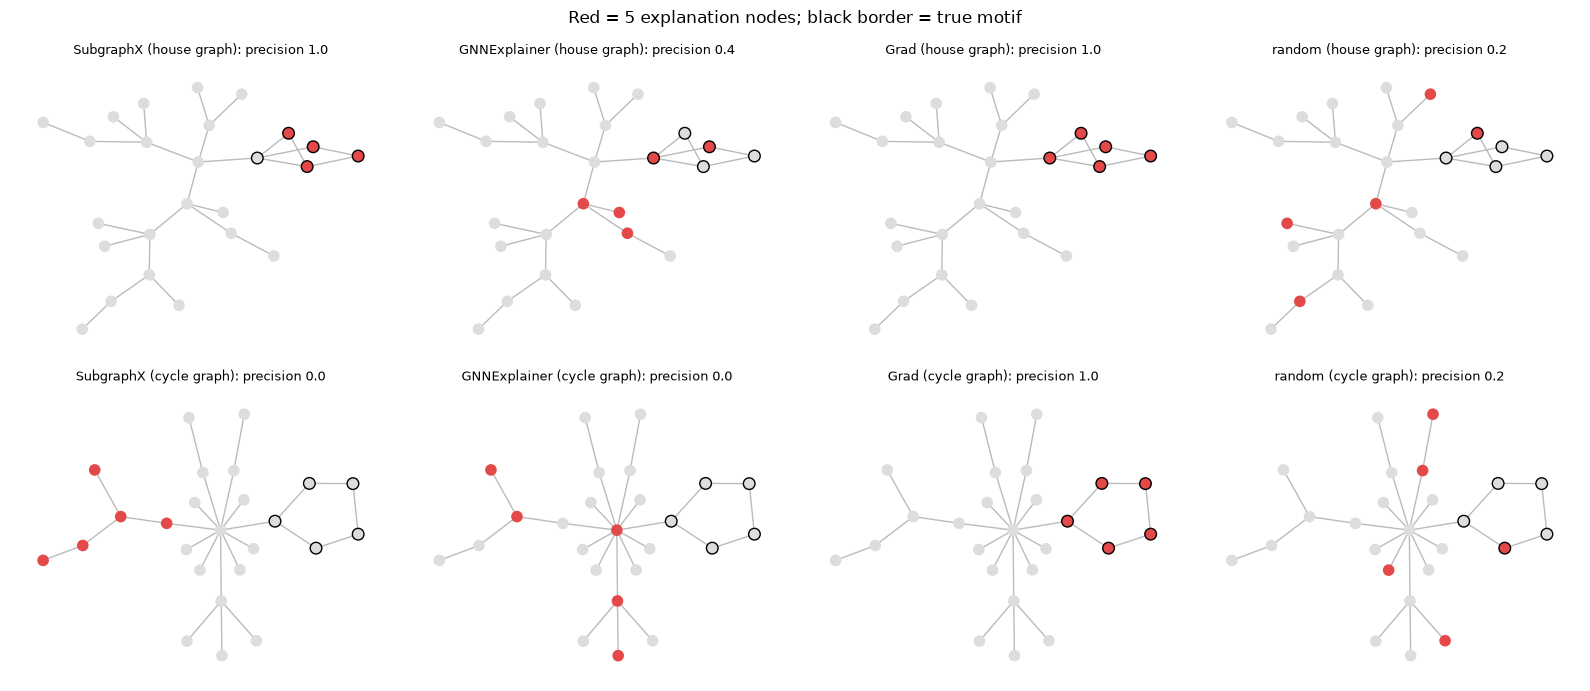

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for row, (offset, label) in enumerate([(0, 'house'), (50, 'cycle')]):
    for col, name in enumerate(['SubgraphX', 'GNNExplainer', 'Grad', 'random']):
        d, S = explained_graphs[offset], NODE_EXPL[name][offset]
        G = nx.Graph(d.edge_index.t().tolist())
        pos = nx.kamada_kawai_layout(G)
        ax = axes[row, col]
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#bbbbbb')
        nx.draw_networkx_nodes(G, pos, ax=ax, node_size=70, node_color=['#e34948' if n in S else '#dddddd' for n in G],
                               edgecolors=['black' if n >= 20 else 'none' for n in G])
        ax.set_title(f'{name} ({label} graph): precision {precision(S):.1f}', fontsize=9); ax.axis('off')
plt.suptitle('Red = 5 explanation nodes; black border = true motif'); plt.tight_layout(); plt.show()

## 5.3. Fidelity: does the explanation carry the prediction?

Ground-truth motifs are only available on synthetic data. Fidelity measures the explanation against the model itself (the metrics of the explainability surveys and of GraphFramEx). With $p(\cdot)$ the probability of the predicted class $\hat y$:
* $\mathrm{Fid}^- = p(G) - p(G_S)$: keep only the explanation. A small value means the explanation is sufficient.
* $\mathrm{Fid}^+ = p(G) - p(G\setminus G_S)$: remove the explanation. A large value means it is necessary.

Here a removed node is deleted with its edges (the model sees the induced subgraph). Zero-filling the features, SubgraphX's choice, is a poor removal on this dataset: with 20 of 25 nodes zero-filled, the model no longer finds the house even when the house is kept.

In [19]:
@torch.no_grad()
def fidelity(model, graphs, node_sets, targets):
    """Fid- (keep only the explanation) and Fid+ (remove it); removed nodes are deleted together with their edges."""
    xb, eb, yb, bb = collate(graphs)
    keep = torch.zeros(xb.size(0), device=device)
    start = 0
    for S, d in zip(node_sets, graphs):
        keep[start + torch.tensor(S, device=device)] = 1.0
        start += d.num_nodes
    def p(present):   # induced subgraph on the present nodes: no messages to / from absent nodes, absent nodes not pooled
        em = present[eb[0]] * present[eb[1]]
        out = model(xb, eb, bb, len(graphs), edge_mask=em, node_weight=present)
        return F.softmax(out, -1).gather(1, targets[:, None]).squeeze(1)
    full = p(torch.ones_like(keep))
    return full - p(keep), full - p(1 - keep)

print(f"{'method':<13}{'Fid- house':>11}{'Fid+ house':>11}{'Fid- cycle':>11}{'Fid+ cycle':>11}")
for name, sets in NODE_EXPL.items():
    fm, fp = fidelity(gmodel, explained_graphs, sets, gb_target)
    print(f'{name:<13}{fm[:50].mean():>11.3f}{fp[:50].mean():>11.3f}{fm[50:].mean():>11.3f}{fp[50:].mean():>11.3f}')

method        Fid- house Fid+ house Fid- cycle Fid+ cycle
SubgraphX          0.840      0.963     -0.000      0.000
GNNExplainer       0.980      0.656     -0.000     -0.000
Grad              -0.000      1.000     -0.000      0.000
random             1.000      0.680     -0.000     -0.000


# Part II. Generalizability

Generalisation. For a GNN $f_\theta$ trained on $\mathcal D_{train} = \{(G_i, y_i)\}_{i=1}^N$, the empirical risk is $\hat{\mathcal R}_S(f_\theta) = \frac1N\sum_i\mathcal L(f_\theta(G_i), y_i)$ and the expected risk on the source distribution is $\mathcal R_S(f_\theta) = \mathbb E_{(G,Y)\sim P_S}[\mathcal L(f_\theta(G), Y)]$. 

The generalisation gap is $\mathcal R_S - \hat{\mathcal R}_S$. 

Out-of-distribution (OOD) generalisation asks about $\mathcal R_T$ under a *different* test distribution $P_T$.

Two kinds of shift, with $U$ the input graph:
* covariate shift: $P(U)$ changes, $P(Y\mid U)$ does not (e.g. larger test graphs);
* concept shift: $P(Y\mid U)$ changes.

A typical failure is shortcut learning: a background structure that is correlated with the label in the training data is easier to use than the motif that really defines the label.

# 6. Spurious-Motif: shortcut learning and size shift

The Spurious-Motif: every graph is a base (tree, ladder or wheel) with one attached 5-node motif (cycle, house or crane). The label is the motif only, $Y = f^*(G_{core})$. In the training set, the base is chosen to "match" the label with probability $b$ (the bias) and is one of the two other bases otherwise. So $P_S(Y\mid G_{background})$ is very informative, although the background does not define the label.

As in DIR, all node features are equal; only the structure is informative.

train            : 3000 graphs | base matches the label in 90% | mean nodes 24.8
ID test          : 1000 graphs | base matches the label in 89% | mean nodes 24.8
OOD test         : 2000 graphs | base matches the label in 34% | mean nodes 24.8
OOD, large bases : 2000 graphs | base matches the label in 34% | mean nodes 54.8


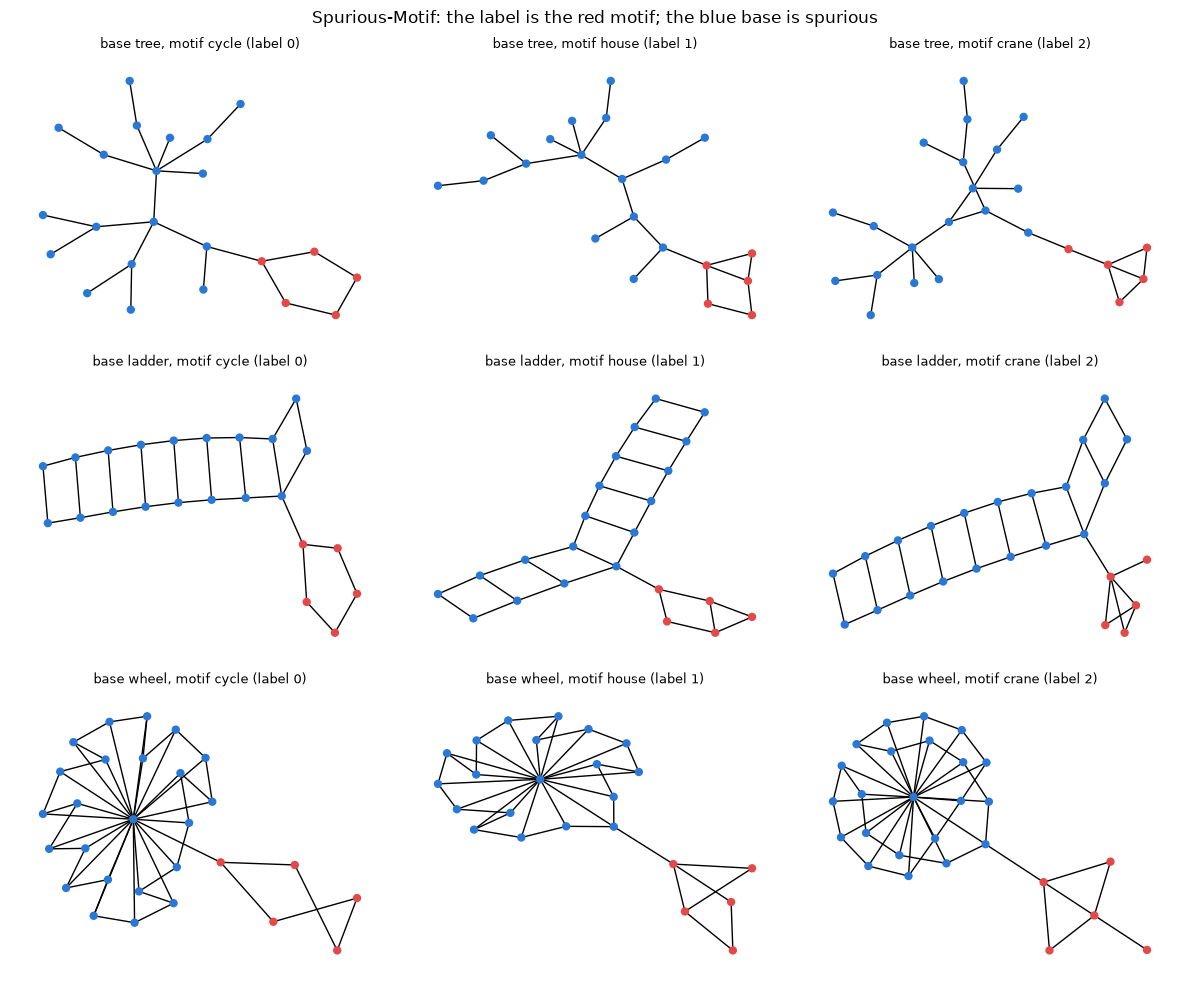

In [20]:
MOTIFS = {'cycle': [(0, 1), (1, 2), (2, 3), (3, 4), (4, 0)],
          'house': [(0, 1), (1, 2), (2, 3), (3, 0), (4, 0), (4, 1)],
          'crane': [(0, 1), (1, 2), (2, 3), (3, 0), (0, 2), (2, 4)]}     # label = position in this dict
BASES = ['tree', 'ladder', 'wheel']

def base_graph(kind, n, rng):
    if kind == 'tree':                    # random tree: node k links to a random earlier node
        return [(k, int(rng.integers(k))) for k in range(1, n)], n
    if kind == 'ladder':                  # two paths of n/2 nodes joined by rungs
        L = n // 2
        return [(i, i + 1) for i in range(L - 1)] + [(L + i, L + i + 1) for i in range(L - 1)] + [(i, L + i) for i in range(L)], 2 * L
    # wheel: hub 0 + cycle 1..n-1
    return [(0, i) for i in range(1, n)] + [(i, i + 1) for i in range(1, n - 1)] + [(n - 1, 1)], n

def spurious_motif(num_graphs, bias, base_sizes=(16, 24), seed=0):
    rng = np.random.default_rng(seed)
    graphs = []
    for _ in range(num_graphs):
        label = int(rng.integers(3))
        # ★ KEY: the spurious correlation: base = label with probability `bias` (1/3 = no correlation).
        base = label if rng.random() < bias else int(rng.choice([b for b in range(3) if b != label]))
        e_base, n_b = base_graph(BASES[base], int(rng.integers(base_sizes[0], base_sizes[1] + 1)), rng)
        e_motif = [(a + n_b, c + n_b) for a, c in MOTIFS[list(MOTIFS)[label]]]
        attach = (n_b + int(rng.integers(5)), int(rng.integers(n_b)))
        e = torch.tensor(e_base + e_motif + [attach]).t()
        ei = torch.cat([e, e.flip(0)], 1)
        graphs.append(SimpleNamespace(x=torch.ones(n_b + 5, 1), edge_index=ei, y=torch.tensor([label]),
                                      num_nodes=n_b + 5, base=base, gt=(ei >= n_b).all(0)))   # gt = motif edges
    return graphs

sp_train = spurious_motif(3000, 0.9, seed=1)
sp_id = spurious_motif(1000, 0.9, seed=2)                        # same distribution as the training set
sp_ood = spurious_motif(2000, 1 / 3, seed=3)                     # base independent of the label
sp_big = spurious_motif(2000, 1 / 3, base_sizes=(40, 60), seed=4)  # ... and larger bases
for name, gs in [('train', sp_train), ('ID test', sp_id), ('OOD test', sp_ood), ('OOD, large bases', sp_big)]:
    match = np.mean([d.base == int(d.y) for d in gs])
    print(f'{name:<17}: {len(gs)} graphs | base matches the label in {match:.0%} | mean nodes {np.mean([d.num_nodes for d in gs]):.1f}')

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
examples = spurious_motif(400, 1 / 3, seed=5)
for b in range(3):
    for c in range(3):
        d = next(g for g in examples if g.base == b and int(g.y) == c)
        G = nx.Graph(d.edge_index.t().tolist())
        ax = axes[b, c]
        pos = nx.kamada_kawai_layout(G)
        nx.draw(G, pos, ax=ax, node_size=25, node_color=['#e34948' if n >= d.num_nodes - 5 else '#2a78d6' for n in G])
        ax.set_title(f'base {BASES[b]}, motif {list(MOTIFS)[c]} (label {c})', fontsize=9)
plt.suptitle('Spurious-Motif: the label is the red motif; the blue base is spurious'); plt.tight_layout(); plt.show()

ERM. We train a 3-layer GNN (sum aggregation and sum pooling, no batch normalisation) with empirical risk minimisation, for 3 seeds. Besides the accuracy on every test set, we split the graphs into majority graphs (base matches the label, 90% of the training set) and minority graphs (base does not match): a model that uses the shortcut fails on the minority graphs.

In [21]:
@torch.no_grad()
def graph_predictions(model, graphs, bs=512):
    model.eval()
    preds = []
    for i in range(0, len(graphs), bs):
        xb, eb, _, bb = collate(graphs[i:i + bs])
        preds.append(model(xb, eb, bb).argmax(1))
    return torch.cat(preds)

def evaluate_sp(predict_fn, graphs):
    pred = predict_fn(graphs).cpu()
    y_ = torch.tensor([int(d.y) for d in graphs]); base = torch.tensor([d.base for d in graphs])
    ok, maj = pred == y_, base == y_
    return ok.float().mean().item(), ok[maj].float().mean().item(), ok[~maj].float().mean().item(), (pred == base).float().mean().item()

SP_RESULTS = {}
for seed in range(3):
    set_seed(seed)
    erm = train_graph_model(GraphGNN(1, 32, 3, pool='sum', bn=False), sp_train, epochs=100, lr=0.001)
    pf = lambda gs, m=erm: graph_predictions(m, gs)
    SP_RESULTS.setdefault('ERM', []).append([evaluate_sp(pf, gs) for gs in (sp_train, sp_id, sp_ood, sp_big)])

def sp_table(results):
    print(f"{'model':<13}{'train':>8}{'ID test':>9}{'OOD':>8}{'OOD large':>11}{'OOD majority':>14}{'OOD minority':>14}{'OOD pred = base':>17}")
    for name, runs in results.items():
        r = np.array(runs)                                                 # [seeds, sets, 4]
        m, s = r.mean(0), r.std(0)
        cells = [f'{m[i, 0]:.3f}' for i in range(4)] + [f'{m[2, 1]:.3f}', f'{m[2, 2]:.3f}', f'{m[2, 3]:.3f}']
        print(f'{name:<13}{cells[0]:>8}{cells[1]:>9}{cells[2]:>8}{cells[3]:>11}{cells[4]:>14}{cells[5]:>14}{cells[6]:>17}'
              f'   (OOD std {s[2, 0]:.3f})')
sp_table(SP_RESULTS)

model           train  ID test     OOD  OOD large  OOD majority  OOD minority  OOD pred = base
ERM             0.904    0.893   0.375      0.378         0.999         0.059            0.938   (OOD std 0.034)


# 7. Self-supervised pre-training: GraphCL and attribute masking 

Pre-training learns reusable representations from unlabelled graphs.

GraphCL: two random augmentations $\hat G_i, \hat G_j$ of the same graph are encoded by a shared GNN $f(\cdot)$ and a projection head $g(\cdot)$ (a 2-layer MLP), and the NT-Xent loss pulls the two views together and pushes the other graphs of the batch away:

$$\ell_n = -\log\frac{\exp(\mathrm{sim}(z_{n,i}, z_{n,j})/\tau)}{\sum_{n'=1, n'\ne n}^{N}\exp(\mathrm{sim}(z_{n,i}, z_{n',j})/\tau)},\qquad \mathrm{sim} = \text{cosine},\ \tau = 0.2 .$$

The four augmentations drop 20% of the nodes, perturb 20% of the edges, mask 20% of the node attributes, or keep a connected subgraph with 80% of the nodes.

Attribute masking is a node-level, predictive task, like masked language modelling in BERT: hide the atom type of 15% of the nodes and predict it from the node embedding, $\mathcal L = \sum_{v\in V_{mask}}\mathrm{CE}(f(h_v^{(K)}), a_v)$.

We pre-train a GIN encoder (3 layers, 32 features, sum pooling of the concatenated layers) on the NCI1 molecules without their labels, freeze it, and evaluate the graph embeddings with a linear classifier (10-fold cross-validation), as in GraphCL's unsupervised protocol. The baseline is the same encoder with random weights.

In [22]:
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    nci1 = TUDataset(ROOT, 'NCI1')
nci_graphs = [SimpleNamespace(x=d.x, edge_index=d.edge_index, y=d.y, num_nodes=d.num_nodes) for d in nci1]
nci_y = torch.cat([d.y for d in nci_graphs]).to(device)
print(f'NCI1: {len(nci_graphs)} molecules | {nci1.num_features} atom types | mean nodes {np.mean([d.num_nodes for d in nci_graphs]):.1f} | classes {torch.bincount(nci_y).tolist()}')

def induced(d, keep):
    idx = keep.nonzero().view(-1)
    rel = torch.full((d.num_nodes,), -1, dtype=torch.long); rel[idx] = torch.arange(idx.numel())
    e = d.edge_index[:, keep[d.edge_index[0]] & keep[d.edge_index[1]]]
    return SimpleNamespace(x=d.x[idx], edge_index=rel[e], y=d.y, num_nodes=idx.numel())

def node_dropping(d, ratio=0.2):
    keep = torch.rand(d.num_nodes) >= ratio
    keep[torch.randint(d.num_nodes, (1,))] = True                     # never drop every node
    return induced(d, keep)

def edge_perturbation(d, ratio=0.2):
    und = d.edge_index[:, d.edge_index[0] < d.edge_index[1]]
    kept = und[:, torch.rand(und.size(1)) >= ratio]
    new = torch.randint(d.num_nodes, (2, und.size(1) - kept.size(1)))   # as many random edges as dropped ones
    e = torch.cat([kept, new[:, new[0] != new[1]]], 1)
    return SimpleNamespace(x=d.x, edge_index=torch.cat([e, e.flip(0)], 1), y=d.y, num_nodes=d.num_nodes)

def attribute_masking(d, ratio=0.2):
    x = d.x.clone()
    x[torch.rand(d.num_nodes) < ratio] = 0.0
    return SimpleNamespace(x=x, edge_index=d.edge_index, y=d.y, num_nodes=d.num_nodes)

def subgraph_extraction(d, ratio=0.2):
    """Grow a connected subgraph from a random node (random neighbour expansion) until (1 - ratio) of the nodes."""
    nbrs = [[] for _ in range(d.num_nodes)]
    for a, b in d.edge_index.t().tolist():
        nbrs[a].append(b)
    start = int(torch.randint(d.num_nodes, (1,)))
    keep, frontier = {start}, set(nbrs[start])
    while len(keep) < max(1, round((1 - ratio) * d.num_nodes)) and frontier:
        v = random.choice(sorted(frontier))
        keep.add(v); frontier |= set(nbrs[v]); frontier -= keep
    mask = torch.zeros(d.num_nodes, dtype=torch.bool); mask[list(keep)] = True
    return induced(d, mask)

AUGS = {'NodeDrop': node_dropping, 'EdgePert': edge_perturbation, 'AttrMask': attribute_masking, 'Subgraph': subgraph_extraction}
d = nci_graphs[0]
for name, aug in AUGS.items():
    a = aug(d)
    print(f'{name:<9}: {d.num_nodes} nodes / {d.edge_index.size(1) // 2} edges -> {a.num_nodes} / {a.edge_index.size(1) // 2}, '
          f'masked atoms: {int((a.x.sum(1) == 0).sum())}')

NCI1: 4110 molecules | 37 atom types | mean nodes 29.9 | classes [2053, 2057]
NodeDrop : 21 nodes / 21 edges -> 17 / 12, masked atoms: 0
EdgePert : 21 nodes / 21 edges -> 21 / 21, masked atoms: 0
AttrMask : 21 nodes / 21 edges -> 21 / 21, masked atoms: 4
Subgraph : 21 nodes / 21 edges -> 17 / 17, masked atoms: 0


In [23]:
class GIN(nn.Module):
    """GIN encoder: h_i' = MLP(h_i + Σ_j h_j) with BN + ReLU; graph embedding = concatenated sum-pooled layers."""
    def __init__(self, in_dim, hidden=32, num_layers=3):
        super().__init__()
        self.mlps = nn.ModuleList([nn.Sequential(nn.Linear(in_dim if l == 0 else hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
                                   for l in range(num_layers)])
        self.bns = nn.ModuleList([nn.BatchNorm1d(hidden) for _ in range(num_layers)])
        self.out_dim = hidden * num_layers

    def node_embed(self, x, edge_index):
        hs = []
        for mlp, bn in zip(self.mlps, self.bns):
            x = F.relu(bn(mlp(x + scatter_sum(x[edge_index[0]], edge_index[1], x.size(0)))))
            hs.append(x)
        return torch.cat(hs, -1)

    def forward(self, x, edge_index, batch, num_graphs):
        return scatter_sum(self.node_embed(x, edge_index), batch, num_graphs)

def nt_xent(z1, z2, tau=0.2):
    """NT-Xent: the positive is the other view of the same graph, the negatives the other graphs' views."""
    z1, z2 = F.normalize(z1, dim=1), F.normalize(z2, dim=1)
    sim = z1 @ z2.t() / tau                                             # sim[n, n'] = cos(z_{n,i}, z_{n',j}) / τ
    neg = sim.masked_fill(torch.eye(sim.size(0), dtype=torch.bool, device=sim.device), -float('inf'))
    # ★ KEY: ℓ_n = -sim(n, n) + log Σ_{n' ≠ n} exp(sim(n, n'))  (the denominator excludes n' = n).
    return (-sim.diag() + torch.logsumexp(neg, dim=1)).mean()

def pretrain_graphcl(encoder, graphs, aug1='NodeDrop', aug2='Subgraph', epochs=20, bs=128, lr=0.01, tau=0.2):
    head = nn.Sequential(nn.Linear(encoder.out_dim, encoder.out_dim), nn.ReLU(), nn.Linear(encoder.out_dim, encoder.out_dim)).to(device)
    opt = torch.optim.Adam(list(encoder.parameters()) + list(head.parameters()), lr=lr)
    for epoch in range(epochs):
        encoder.train()
        perm = torch.randperm(len(graphs)).tolist()
        for i in range(0, len(perm), bs):
            chunk = [graphs[j] for j in perm[i:i + bs]]
            x1, e1, _, b1 = collate([AUGS[aug1](d) for d in chunk])
            x2, e2, _, b2 = collate([AUGS[aug2](d) for d in chunk])
            loss = nt_xent(head(encoder(x1, e1, b1, len(chunk))), head(encoder(x2, e2, b2, len(chunk))), tau)
            opt.zero_grad(); loss.backward(); opt.step()
    return encoder

def pretrain_attrmask(encoder, graphs, num_types, epochs=20, bs=128, lr=0.01, ratio=0.15):
    head = nn.Linear(encoder.out_dim, num_types).to(device)           # linear classifier on the node embedding
    opt = torch.optim.Adam(list(encoder.parameters()) + list(head.parameters()), lr=lr)
    for epoch in range(epochs):
        encoder.train()
        perm = torch.randperm(len(graphs)).tolist()
        for i in range(0, len(perm), bs):
            xb, eb, _, bb = collate([graphs[j] for j in perm[i:i + bs]])
            atom = xb.argmax(1)
            masked = torch.rand(xb.size(0), device=device) < ratio
            # ★ KEY: hide the attributes of the masked atoms, then predict their type from the context.
            h = encoder.node_embed(xb.masked_fill(masked[:, None], 0.0), eb)
            loss = F.cross_entropy(head(h[masked]), atom[masked])
            opt.zero_grad(); loss.backward(); opt.step()
    return encoder

@torch.no_grad()
def embed_graphs(encoder, graphs, bs=1024):
    encoder.eval()
    out = []
    for i in range(0, len(graphs), bs):
        xb, eb, _, bb = collate(graphs[i:i + bs])
        out.append(encoder(xb, eb, bb, len(graphs[i:i + bs])))
    return torch.cat(out)

def linear_probe(Z, y, folds=10, seed=0, epochs=300, lr=0.01, wd=1e-3):
    """Mean ± std accuracy of a logistic-regression classifier on frozen, standardised embeddings (k-fold CV)."""
    perm = torch.randperm(Z.size(0), generator=torch.Generator().manual_seed(seed)).to(Z.device)
    accs = []
    for f in range(folds):
        te = perm[f::folds]; tr = perm[~torch.isin(perm, te)]
        mu, sd = Z[tr].mean(0), Z[tr].std(0) + 1e-6
        clf = nn.Linear(Z.size(1), int(y.max()) + 1).to(Z.device)
        opt = torch.optim.Adam(clf.parameters(), lr=lr, weight_decay=wd)
        for _ in range(epochs):
            opt.zero_grad(); F.cross_entropy(clf((Z[tr] - mu) / sd), y[tr]).backward(); opt.step()
        accs.append((clf((Z[te] - mu) / sd).argmax(1) == y[te]).float().mean().item())
    return float(np.mean(accs)), float(np.std(accs))

PRE_RESULTS = {}
for seed in range(2):
    set_seed(seed)
    PRE_RESULTS.setdefault('random init', []).append(linear_probe(embed_graphs(GIN(37).to(device), nci_graphs), nci_y)[0])
    set_seed(seed); t0 = time.time()
    enc = pretrain_graphcl(GIN(37).to(device), nci_graphs)
    t_cl = time.time() - t0
    PRE_RESULTS.setdefault('GraphCL', []).append(linear_probe(embed_graphs(enc, nci_graphs), nci_y)[0])
    set_seed(seed); t0 = time.time()
    enc = pretrain_attrmask(GIN(37).to(device), nci_graphs, 37)
    t_am = time.time() - t0
    PRE_RESULTS.setdefault('AttrMask', []).append(linear_probe(embed_graphs(enc, nci_graphs), nci_y)[0])
for name, accs in PRE_RESULTS.items():
    print(f'{name:<12}: linear-probe accuracy {np.mean(accs) * 100:.1f} ± {np.std(accs) * 100:.1f} (2 seeds, 10 folds each)')
print(f'Pre-training time (20 epochs): GraphCL {t_cl:.0f}s, attribute masking {t_am:.0f}s')

random init : linear-probe accuracy 69.5 ± 0.1 (2 seeds, 10 folds each)
GraphCL     : linear-probe accuracy 73.9 ± 0.6 (2 seeds, 10 folds each)
AttrMask    : linear-probe accuracy 72.2 ± 0.1 (2 seeds, 10 folds each)
Pre-training time (20 epochs): GraphCL 47s, attribute masking 11s


# 8. G-Mixup: mixing graph generators

Mixup interpolates inputs and labels, $x_{new} = \lambda x_i + (1-\lambda)x_j$. Graphs cannot be interpolated directly: they have different sizes and no node alignment. G-Mixup mixes their generators instead:

1. Graphon estimation. A graphon $W:[0,1]^2\to[0,1]$ gives the edge probability between two positions. For every graph we sort the nodes by degree and average the adjacency matrix over a $K\times K$ grid of $[0,1]^2$: this is the step function of the graph. A class graphon is the mean step function of the class, smoothed by universal singular value thresholding (as in the G-Mixup code).
2. Graphon mixup: $W_{mix} = \lambda W_i + (1-\lambda)W_j$ with $\lambda\in[0.1, 0.2]$.
3. Sampling: $A_{uv}\sim\mathrm{Bernoulli}(W_{mix}(u, v))$ on the grid; the label is $\lambda y_i + (1-\lambda)y_j$.

We use IMDB-BINARY (1,000 ego networks of actors, 2 movie genres, no node features: we use one-hot degrees) with $K$ = the median graph size, and add 20% synthetic graphs to every training set.

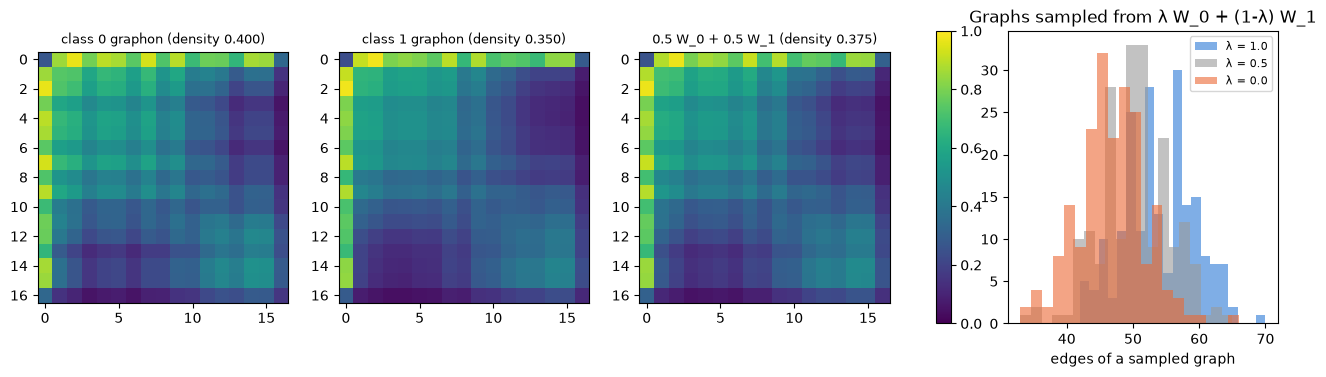

K = 17 | real graphs: mean edges class 0 96.8, class 1 96.3


In [24]:
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    imdb = TUDataset(ROOT, 'IMDB-BINARY')
MAX_DEG = 135                                                   # largest degree in IMDB-BINARY

def with_degree_features(edge_index, n, y):
    deg = torch.zeros(n, dtype=torch.long).index_add_(0, edge_index[0], torch.ones(edge_index.size(1), dtype=torch.long))
    return SimpleNamespace(x=F.one_hot(deg.clamp(max=MAX_DEG), MAX_DEG + 1).float(), edge_index=edge_index, y=y, num_nodes=n)

imdb_graphs = [with_degree_features(d.edge_index, d.num_nodes, F.one_hot(d.y, 2).float()) for d in imdb]   # soft labels
imdb_labels = torch.tensor([int(d.y) for d in imdb])
K = int(np.median([d.num_nodes for d in imdb]))

def step_function(edge_index, n, K):
    """Step function of one graph on a K x K grid: nodes sorted by degree, adjacency averaged over the grid cells."""
    A_ = torch.zeros(n, n); A_[edge_index[0], edge_index[1]] = 1.0
    order = torch.argsort(A_.sum(1), descending=True)
    A_ = A_[order][:, order]
    cell = torch.clamp(torch.arange(n) * K // n, max=K - 1)            # grid cell of node i: [i/n, (i+1)/n) ⊂ [0, 1]
    P = torch.zeros(K, n); P[cell, torch.arange(n)] = 1.0
    P = P / P.sum(1, keepdim=True).clamp(min=1)
    return P @ A_ @ P.t()

def estimate_graphon(graphs, K, threshold=0.2):
    W = torch.stack([step_function(d.edge_index, d.num_nodes, K) for d in graphs]).mean(0)
    U, s, Vh = torch.linalg.svd(W)
    s[s < threshold * math.sqrt(K)] = 0.0                              # universal singular value thresholding
    return (U @ torch.diag(s) @ Vh).clamp(0, 1)

def sample_graph(W, gen):
    A_ = (torch.rand(W.shape, generator=gen) < W).float().triu(1)
    A_ = A_ + A_.t()
    keep = A_.sum(1) > 0                                               # drop isolated nodes
    A_ = A_[keep][:, keep]
    return A_.nonzero().t(), int(keep.sum())

def g_mixup(graphons, num_new, lam_range, gen):
    C, new = len(graphons), []
    for _ in range(num_new):
        i, j = torch.randperm(C, generator=gen)[:2].tolist()
        lam = float(lam_range[0] + (lam_range[1] - lam_range[0]) * torch.rand(1, generator=gen))
        # ★ KEY: mix the generators, W_mix = λ W_i + (1 - λ) W_j, and the labels with the same λ.
        ei, n = sample_graph(lam * graphons[i] + (1 - lam) * graphons[j], gen)
        y_soft = torch.zeros(1, C); y_soft[0, i] += lam; y_soft[0, j] += 1 - lam
        new.append(with_degree_features(ei, max(n, 1), y_soft))
    return new

W_class = [estimate_graphon([imdb[i] for i in range(len(imdb)) if imdb_labels[i] == c], K) for c in range(2)]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (title, W) in zip(axes, [('class 0 graphon', W_class[0]), ('class 1 graphon', W_class[1]),
                                 ('0.5 W_0 + 0.5 W_1', 0.5 * W_class[0] + 0.5 * W_class[1])]):
    im = ax.imshow(W, cmap='viridis', vmin=0, vmax=1); ax.set_title(f'{title} (density {W.mean():.3f})', fontsize=9)
plt.colorbar(im, ax=axes[:3], fraction=0.02)
gen = torch.Generator().manual_seed(0)
for lam, c in [(1.0, '#2a78d6'), (0.5, '#9a9a9a'), (0.0, '#eb6834')]:
    dens = [sample_graph(lam * W_class[0] + (1 - lam) * W_class[1], gen) for _ in range(200)]
    axes[3].hist([e.size(1) / 2 for e, n in dens], bins=20, alpha=0.6, color=c, label=f'λ = {lam}')
axes[3].set(xlabel='edges of a sampled graph', title='Graphs sampled from λ W_0 + (1-λ) W_1'); axes[3].legend(fontsize=8)
plt.show()
print(f'K = {K} | real graphs: mean edges class 0 {np.mean([d.edge_index.size(1) / 2 for d, c in zip(imdb, imdb_labels) if c == 0]):.1f}, '
      f'class 1 {np.mean([d.edge_index.size(1) / 2 for d, c in zip(imdb, imdb_labels) if c == 1]):.1f}')

In [25]:
class GraphClassifier(nn.Module):
    def __init__(self, in_dim, hidden, num_classes):
        super().__init__()
        self.enc = GIN(in_dim, hidden, 3)
        self.head = nn.Sequential(nn.Linear(self.enc.out_dim, hidden), nn.ReLU(), nn.Linear(hidden, num_classes))
    def forward(self, x, edge_index, batch, num_graphs):
        return self.head(self.enc(x, edge_index, batch, num_graphs))

def collate_soft(graphs):
    xs = [SimpleNamespace(x=g.x, edge_index=g.edge_index, y=torch.zeros(1), num_nodes=g.num_nodes) for g in graphs]
    xb, eb, _, bb = collate(xs)
    return xb, eb, torch.cat([g.y for g in graphs]).to(device), bb

def train_soft(train_graphs, val_graphs, test_graphs, epochs=100, bs=128, lr=0.01, seed=0):
    """Soft-label cross-entropy; returns the test accuracy at the epoch with the best validation accuracy."""
    set_seed(seed)
    model = GraphClassifier(MAX_DEG + 1, 64, 2).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_val, best_test = -1, 0
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(train_graphs)).tolist()
        for i in range(0, len(perm), bs):
            chunk = [train_graphs[j] for j in perm[i:i + bs]]
            xb, eb, yb, bb = collate_soft(chunk)
            loss = -(yb * F.log_softmax(model(xb, eb, bb, len(chunk)), -1)).sum(1).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            accs = []
            for gs in (val_graphs, test_graphs):
                xb, eb, yb, bb = collate_soft(gs)
                accs.append((model(xb, eb, bb, len(gs)).argmax(1) == yb.argmax(1)).float().mean().item())
        if accs[0] > best_val:
            best_val, best_test = accs
    return best_test

MIX_RESULTS = {'GIN': [], 'GIN + G-Mixup': []}
for seed in range(5):                                            # 5 random 70 / 10 / 20 splits
    perm = torch.randperm(len(imdb_graphs), generator=torch.Generator().manual_seed(seed)).tolist()
    tr_g = [imdb_graphs[i] for i in perm[:700]]
    va_g, te_g = [imdb_graphs[i] for i in perm[700:800]], [imdb_graphs[i] for i in perm[800:]]
    W = [estimate_graphon([imdb[i] for i in perm[:700] if imdb_labels[i] == c], K) for c in range(2)]   # training graphs only
    synthetic = g_mixup(W, int(0.2 * len(tr_g)), (0.1, 0.2), torch.Generator().manual_seed(seed))
    MIX_RESULTS['GIN'].append(train_soft(tr_g, va_g, te_g, seed=seed))
    MIX_RESULTS['GIN + G-Mixup'].append(train_soft(tr_g + synthetic, va_g, te_g, seed=seed))
for name, accs in MIX_RESULTS.items():
    print(f'{name:<14}: test accuracy {np.mean(accs) * 100:.1f} ± {np.std(accs) * 100:.1f}  (splits: {", ".join(f"{a * 100:.1f}" for a in accs)})')

GIN           : test accuracy 73.5 ± 3.3  (splits: 70.0, 74.0, 69.5, 78.0, 76.0)
GIN + G-Mixup : test accuracy 72.5 ± 3.9  (splits: 68.0, 75.5, 68.0, 77.5, 73.5)


# 9. EERM: exploring virtual environments

For node classification there is usually one training graph, i.e. one environment, so invariant learning cannot compare environments. EERM creates $K$ virtual environments with graph editors: editor $k$ has a parameter matrix $B^k$ and, for every node $i$, flips $s$ edges $(i, j)$ with $j\sim\mathrm{softmax}(B^k_i)$ (an absent edge is added, a present one removed). The GNN minimises the mean and the variance of its risks on the $K$ edited graphs, while the editors are trained with REINFORCE to maximise the variance:

$$\min_\theta\ \mathrm{Var}\big(\{\mathcal L(G_k)\}_{k=1}^K\big) + \beta\,\frac1K\sum_k\mathcal L(G_k),\qquad \max_{B}\ \mathrm{Var}\big(\{\mathcal L(G_k)\}\big)\ \ (\nabla_B = \mathrm{Var}\cdot\nabla_B\log p_B(G_1,\dots,G_K)).$$

As in the EERM code, the editors are re-initialised at every epoch; $K = 3$, $\beta = 1$ and $s = 20$ flips per node.

Task: a neighbourhood shift. A contextual SBM with 4 classes: node features $x_i = \mu_{y_i} + \varepsilon$ ($\|\mu_c\| = 1.5$, $\varepsilon\sim\mathcal N(0, I_{16})$), 10 edges per node on average.

Training graph: 80% of the edges join nodes of the same class. 

Test graphs: new graphs with the same feature distribution and homophily 0.8, 0.6, 0.4, 0.2 and 0. The node's own features are the invariant signal; the neighbours help only while the homophily stays high.

In [26]:
def csbm_graph(n, C, homophily, avg_deg, means, seed):
    """Contextual SBM: x_i = μ_{y_i} + N(0, I); every edge joins two nodes of the same class with probability `homophily`."""
    g = torch.Generator().manual_seed(seed)
    yy = (torch.arange(n) % C)[torch.randperm(n, generator=g)]
    xx = means[yy] + torch.randn(n, means.size(1), generator=g)
    m = n * avg_deg // 2
    src = torch.randint(n, (m,), generator=g)
    same = torch.rand(m, generator=g) < homophily
    cls = torch.where(same, yy[src], (yy[src] + torch.randint(1, C, (m,), generator=g)) % C)
    by_class = torch.argsort(yy)                                   # class c occupies positions [c n/C, (c+1) n/C)
    dst = by_class[cls * (n // C) + torch.randint(n // C, (m,), generator=g)]
    e = torch.stack([src[src != dst], dst[src != dst]])
    return xx.to(device), torch.unique(torch.cat([e, e.flip(0)], 1), dim=1).to(device), yy.to(device)

class SAGE(nn.Module):
    """2-layer GraphSAGE (mean aggregation): h_i' = W_1 h_i + W_2 mean_{j ∈ N(i)} h_j."""
    def __init__(self, in_dim, hidden, out_dim, dropout=0.5):
        super().__init__()
        self.self1, self.nbr1 = nn.Linear(in_dim, hidden), nn.Linear(in_dim, hidden, bias=False)
        self.self2, self.nbr2 = nn.Linear(hidden, out_dim), nn.Linear(hidden, out_dim, bias=False)
        self.dropout = dropout
    @staticmethod
    def mean_agg(h, edge_index):
        return scatter_sum(h[edge_index[0]], edge_index[1], h.size(0)) / degree(edge_index[1], h.size(0)).clamp(min=1)[:, None]
    def forward(self, x, edge_index):
        h = F.dropout(x, self.dropout, self.training)
        h = F.relu(self.self1(h) + self.nbr1(self.mean_agg(h, edge_index)))
        h = F.dropout(h, self.dropout, self.training)
        return self.self2(h) + self.nbr2(self.mean_agg(h, edge_index))

class MLP(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, dropout=0.5):
        super().__init__()
        self.lin1, self.lin2, self.dropout = nn.Linear(in_dim, hidden), nn.Linear(hidden, out_dim), dropout
    def forward(self, x, edge_index=None):
        h = F.dropout(F.relu(self.lin1(F.dropout(x, self.dropout, self.training))), self.dropout, self.training)
        return self.lin2(h)

class GraphEditor(nn.Module):
    """K editors: editor k flips, for every node i, s edges (i, j) with j ~ softmax(B_k[i])."""
    def __init__(self, K, n):
        super().__init__()
        self.B = nn.Parameter(torch.zeros(K, n, n))
    def reset_parameters(self):
        nn.init.uniform_(self.B)
    def forward(self, edge_index, n, s, k):
        A_ = torch.zeros(n, n, device=device); A_[edge_index[0], edge_index[1]] = 1.0
        cols = torch.multinomial(F.softmax(self.B[k], 1), s)                       # [n, s] sampled partners
        flip = torch.zeros(n, n, device=device)
        flip[torch.arange(n, device=device)[:, None].expand_as(cols), cols] = 1.0
        flip = ((flip + flip.t()) > 0).float()
        A_new = A_ + flip * (1 - 2 * A_)                                             # add absent edges, remove present ones
        A_new.fill_diagonal_(0)
        log_p = F.log_softmax(self.B[k], 1).gather(1, cols).sum()                    # log-probability of the edit
        return A_new.nonzero().t(), log_p

def train_erm(model, xx, ei, yy, idx, epochs=300, lr=0.01):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    for _ in range(epochs):
        model.train(); opt.zero_grad()
        F.cross_entropy(model(xx, ei)[idx], yy[idx]).backward(); opt.step()
    return model

def train_eerm(model, xx, ei, yy, idx, K=3, s=20, beta=1.0, epochs=300, lr=0.01, lr_editor=0.005):
    n = xx.size(0)
    editor = GraphEditor(K, n).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    opt_e = torch.optim.Adam(editor.parameters(), lr=lr_editor)
    for epoch in range(epochs):
        model.train()
        editor.reset_parameters()
        losses, log_p = [], 0.0
        for k in range(K):                                                          # K virtual environments
            ei_k, lp = editor(ei, n, s, k)
            losses.append(F.cross_entropy(model(xx, ei_k)[idx], yy[idx]))
            log_p = log_p + lp
        losses = torch.stack(losses)
        # ★ KEY: the GNN minimises Var + β·Mean of the environment risks ...
        opt.zero_grad(); (losses.var() + beta * losses.mean()).backward(retain_graph=True); opt.step()
        # ★ KEY: ... while the editors maximise the variance (REINFORCE with reward Var).
        opt_e.zero_grad(); (-losses.var().detach() * log_p).backward(); opt_e.step()
    return model

C_, d_, n_ = 4, 16, 2000
g_ = torch.Generator().manual_seed(0)
means = torch.randn(C_, d_, generator=g_)
means = 1.5 * means / means.norm(dim=1, keepdim=True)
x_tr, ei_tr, y_tr = csbm_graph(n_, C_, 0.8, 10, means, seed=1)
idx_tr = torch.randperm(n_, generator=g_)[:n_ // 2].to(device)
test_envs = {h: csbm_graph(n_, C_, h, 10, means, seed=10 + int(10 * h)) for h in [0.8, 0.6, 0.4, 0.2, 0.0]}

@torch.no_grad()
def env_accuracies(model):
    model.eval()
    return [(model(xe, ee).argmax(1) == ye).float().mean().item() for xe, ee, ye in test_envs.values()]

EERM_RESULTS = {}
for seed in range(3):
    set_seed(seed); EERM_RESULTS.setdefault('MLP', []).append(env_accuracies(train_erm(MLP(d_, 32, C_).to(device), x_tr, ei_tr, y_tr, idx_tr)))
    set_seed(seed); EERM_RESULTS.setdefault('ERM (SAGE)', []).append(env_accuracies(train_erm(SAGE(d_, 32, C_).to(device), x_tr, ei_tr, y_tr, idx_tr)))
    set_seed(seed); EERM_RESULTS.setdefault('EERM (SAGE)', []).append(env_accuracies(train_eerm(SAGE(d_, 32, C_).to(device), x_tr, ei_tr, y_tr, idx_tr)))
print(f"{'model':<13}" + ''.join(f'{f"h = {h}":>10}' for h in test_envs))
for name, runs in EERM_RESULTS.items():
    r = np.array(runs)
    print(f'{name:<13}' + ''.join(f'{v:>10.3f}' for v in r.mean(0)) + f'   (max std {r.std(0).max():.3f})')

model           h = 0.8   h = 0.6   h = 0.4   h = 0.2   h = 0.0
MLP               0.669     0.678     0.660     0.671     0.669   (max std 0.004)
ERM (SAGE)        0.988     0.903     0.621     0.429     0.527   (max std 0.019)
EERM (SAGE)       0.987     0.906     0.664     0.430     0.393   (max std 0.005)


# 10. DIR: discovering invariant rationales

Causal view: the input graph $G$ is made of a causal part $C$ (here the motif) and a spurious part $S$ (the base), $C\to Y$, and $S$ is correlated with $Y$ through the environment. A rationale $G_c\subset G$ is invariant if $P(Y\mid G_c)$ is the same in every environment. DIR has four parts:

1. Rationale generator: a GNN scores every edge; the top $r = 25\%$ edges of every graph form $G_c$, the others $G_s$. The messages of $G_c$ are weighted by $\sigma(s_e)$, those of $G_s$ by $1-\sigma(s_e)$, so the generator receives gradients.
2. Shared encoder + two classifiers: the causal classifier $f_c(h_c)$ and the shortcut classifier $f_s(h_s)$, trained on $G_s$ with its own loss (no gradient flows from it into the encoder).
3. Distribution intervener: combining $G_c$ of graph $i$ with $G_s$ of graph $j$ of the batch simulates $do(S = s_j)$. As in the DIR code, the joint prediction is $f_c(h_c^{(i)})\odot\sigma\big(f_s(h_s^{(j)})\big)$ (the shortcut prediction is detached), and $\mathcal L_j$ is its cross-entropy over the batch.
4. Loss: $\mathcal L_{total} = \mathcal L_{pred} + \lambda\,\mathrm{Var}_j(\mathcal L_j)$ with $\mathcal L_{pred}$ the cross-entropy of $f_c$; here $\lambda = 1$. At test time only $f_c(h_c)$ is used.

The encoder is the same GNN as the ERM model.

In [27]:
def topk_per_graph(score, group, ratio, num_groups):
    """Boolean mask of the ceil(ratio · size) items with the largest score inside every group."""
    n = torch.bincount(group, minlength=num_groups)
    k = torch.ceil(ratio * n.float()).long()
    order = torch.argsort(score, descending=True)
    order = order[torch.argsort(group[order], stable=True)]           # sort by group, keep the score order inside
    start = torch.cumsum(n, 0) - n
    rank = torch.empty_like(order)
    rank[order] = torch.arange(order.numel(), device=score.device) - start[group[order]]
    return rank < k[group]

class DIR(nn.Module):
    def __init__(self, in_dim, hidden, num_classes, ratio=0.25):
        super().__init__()
        self.gen = nn.ModuleList([SumConv(in_dim, hidden), SumConv(hidden, hidden)])     # rationale generator
        self.scorer = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
        self.encoder = GraphGNN(in_dim, hidden, num_classes, pool='sum', bn=False)      # shared encoder (its .lin is unused)
        self.f_c = nn.Linear(self.encoder.out_dim, num_classes)                          # causal classifier
        self.f_s = nn.Linear(self.encoder.out_dim, num_classes)                          # shortcut classifier
        self.ratio = ratio

    def split(self, x, edge_index, batch, G):
        h = x
        for conv in self.gen:
            h = F.relu(conv(h, edge_index))
        s = self.scorer(torch.cat([h[edge_index[0]], h[edge_index[1]]], -1)).squeeze(-1)
        und, U = undirected_ids(edge_index, x.size(0))
        s = (scatter_sum(s, und, U) / scatter_sum(torch.ones_like(s), und, U))[und]     # same score for both directions
        s_u = torch.zeros(U, device=x.device).scatter_(0, und, s)
        g_u = torch.zeros(U, dtype=torch.long, device=x.device).scatter_(0, und, batch[edge_index[0]])
        # ★ KEY: the rationale G_c = the top r edges of every graph; the rest is the environment part G_s.
        causal = topk_per_graph(s_u, g_u, self.ratio, G)[und]
        return s, causal

    def readout(self, x, edge_index, weight, batch, G):
        """Encode the subgraph made of the given edges (messages scaled by `weight`); pool over the nodes it touches."""
        present = torch.zeros(x.size(0), device=x.device)
        present[edge_index[0]] = 1.0; present[edge_index[1]] = 1.0
        return self.encoder.pooled(x, edge_index, batch, G, edge_mask=weight, node_weight=present)

    def forward(self, x, edge_index, batch, G):
        s, causal = self.split(x, edge_index, batch, G)
        p = torch.sigmoid(s)
        h_c = self.readout(x, edge_index[:, causal], p[causal], batch, G)
        h_s = self.readout(x, edge_index[:, ~causal], 1 - p[~causal], batch, G)
        return self.f_c(h_c), self.f_s(h_s.detach()), causal

def train_dir(model, graphs, epochs=100, lr=0.001, bs=64, lam=1.0):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(graphs)).tolist()
        for i in range(0, len(perm), bs):
            xb, eb, yb, bb = collate([graphs[j] for j in perm[i:i + bs]])
            G = yb.numel()
            z_c, z_s, _ = model(xb, eb, bb, G)
            # interventions do(S = s_j): causal logits of every graph i, modulated by the shortcut prediction of graph j
            mix = z_c.unsqueeze(0) * torch.sigmoid(z_s.detach()).unsqueeze(1)                  # [j, i, C]
            L_env = F.cross_entropy(mix.reshape(-1, mix.size(-1)), yb.repeat(G), reduction='none').view(G, G).mean(1)
            # ★ KEY: L_total = L_pred + λ Var_j(L_j); the shortcut classifier learns from G_s with its own loss.
            loss = F.cross_entropy(z_c, yb) + lam * L_env.var() + F.cross_entropy(z_s, yb)
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    return model

@torch.no_grad()
def dir_predict(model, graphs, bs=512, return_precision=False):
    model.eval()
    preds, prec = [], []
    for i in range(0, len(graphs), bs):
        chunk = graphs[i:i + bs]
        xb, eb, yb, bb = collate(chunk)
        z_c, _, causal = model(xb, eb, bb, len(chunk))
        preds.append(z_c.argmax(1))
        gt = torch.cat([d.gt for d in chunk]).to(device)
        owner = bb[eb[0]][causal]
        prec.append(scatter_sum(gt[causal].float(), owner, len(chunk)) / torch.bincount(owner, minlength=len(chunk)).clamp(min=1))
    return (torch.cat(preds), torch.cat(prec)) if return_precision else torch.cat(preds)

DIR_MODELS = {}
for lam, name in [(1.0, 'DIR'), (0.0, 'DIR, λ = 0')]:
    for seed in range(3):
        set_seed(seed)
        dm = train_dir(DIR(1, 32, 3), sp_train, lam=lam)
        DIR_MODELS[(name, seed)] = dm
        SP_RESULTS.setdefault(name, []).append([evaluate_sp(lambda gs, m=dm: dir_predict(m, gs), gs) for gs in (sp_train, sp_id, sp_ood, sp_big)])
sp_table(SP_RESULTS)
for name, runs in SP_RESULTS.items():
    print(f'{name:<11} OOD accuracy of every seed: ' + ', '.join(f'{r[2][0]:.3f}' for r in runs))
prec_seeds = [dir_predict(DIR_MODELS[('DIR', s)], sp_ood, return_precision=True)[1].mean().item() for s in range(3)]
prec_ood = np.mean(prec_seeds)
share = np.mean([d.gt.float().mean().item() for d in sp_ood])
print(f'\nRationale precision on the OOD graphs (share of the selected edges that are motif edges): {prec_ood:.3f} '
      f'(random selection: {share:.3f}; at most {np.mean([d.gt.sum().item() / math.ceil(0.25 * d.edge_index.size(1) / 2) / 2 for d in sp_ood]):.3f} '
      f'because the top 25% holds more edges than the motif); per seed: ' + ', '.join(f'{p_:.3f}' for p_ in prec_seeds))

model           train  ID test     OOD  OOD large  OOD majority  OOD minority  OOD pred = base
ERM             0.904    0.893   0.375      0.378         0.999         0.059            0.938   (OOD std 0.034)
DIR             0.945    0.934   0.625      0.494         1.000         0.434            0.669   (OOD std 0.207)
DIR, λ = 0      0.946    0.937   0.635      0.432         0.999         0.451            0.659   (OOD std 0.209)
ERM         OOD accuracy of every seed: 0.419, 0.370, 0.336
DIR         OOD accuracy of every seed: 0.811, 0.727, 0.336
DIR, λ = 0  OOD accuracy of every seed: 0.794, 0.772, 0.340

Rationale precision on the OOD graphs (share of the selected edges that are motif edges): 0.318 (random selection: 0.175; at most 0.666 because the top 25% holds more edges than the motif); per seed: 0.407, 0.361, 0.184


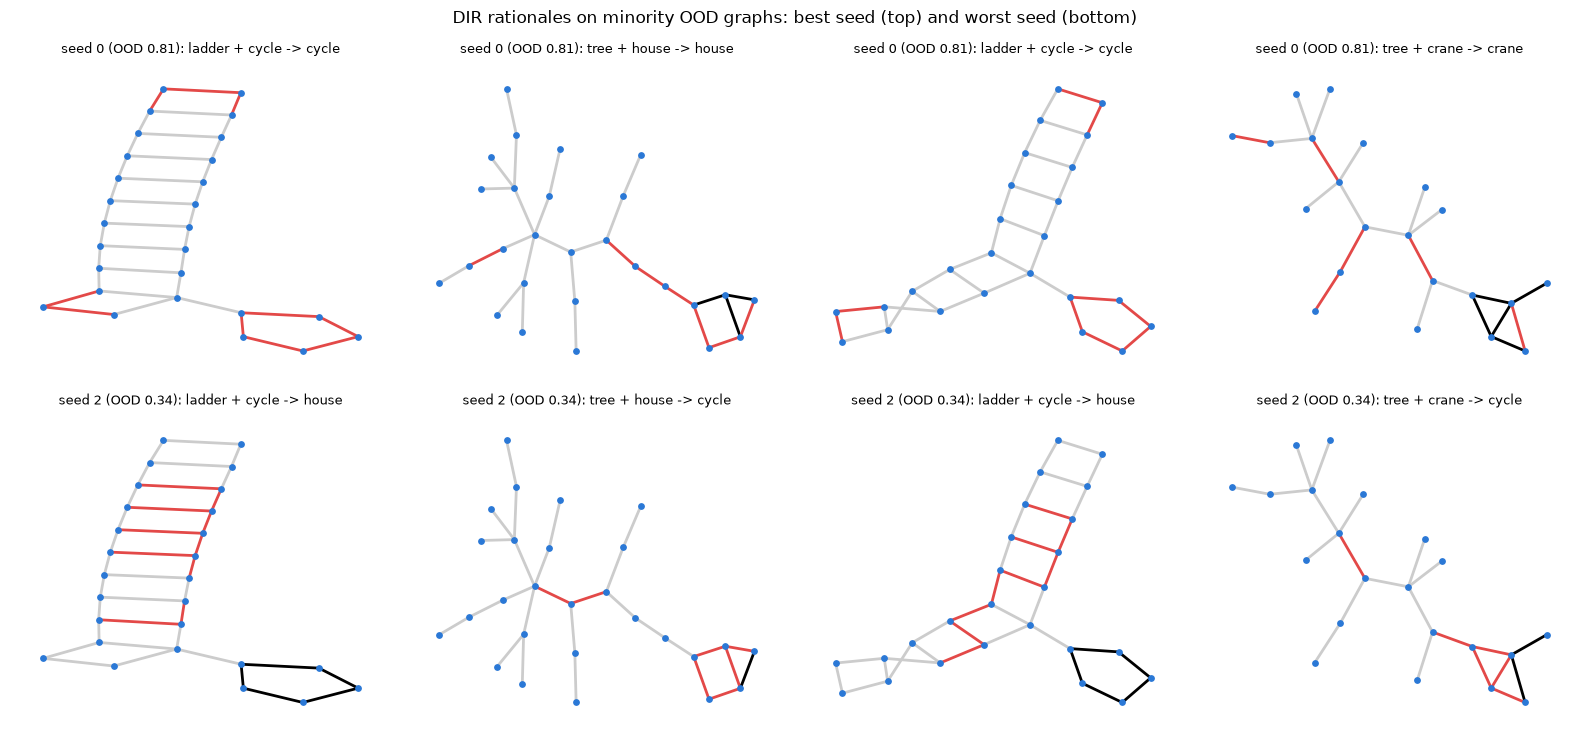

In [28]:
# Rationales of the DIR models with the best and the worst OOD accuracy (red = selected edges, black = motif edges not selected)
ood_acc = {seed: SP_RESULTS['DIR'][seed][2][0] for seed in range(3)}
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
minority = [g for g in sp_ood if g.base != int(g.y)][:4]
for row, seed in enumerate([max(ood_acc, key=ood_acc.get), min(ood_acc, key=ood_acc.get)]):
    dm = DIR_MODELS[('DIR', seed)]
    for ax, d in zip(axes[row], minority):
        xb, eb, yb, bb = collate([d])
        with torch.no_grad():
            z_c, _, causal = dm(xb, eb, bb, 1)
        G = nx.Graph(d.edge_index.t().tolist())
        sel = {tuple(sorted(e)) for e, c in zip(d.edge_index.t().tolist(), causal.tolist()) if c}
        motif = {tuple(sorted(e)) for e, g_ in zip(d.edge_index.t().tolist(), d.gt.tolist()) if g_}
        pos = nx.kamada_kawai_layout(G)
        colors = ['#e34948' if tuple(sorted(e)) in sel else ('black' if tuple(sorted(e)) in motif else '#cccccc') for e in G.edges]
        nx.draw(G, pos, ax=ax, node_size=15, node_color='#2a78d6', edge_color=colors, width=2)
        ax.set_title(f'seed {seed} (OOD {ood_acc[seed]:.2f}): {BASES[d.base]} + {list(MOTIFS)[int(d.y)]} -> {list(MOTIFS)[z_c.argmax().item()]}', fontsize=9)
plt.suptitle('DIR rationales on minority OOD graphs: best seed (top) and worst seed (bottom)'); plt.tight_layout(); plt.show()

# Part III. Robustness

Robustness: a GNN $\hat Y = f_\theta(A, X)$ is robust at node $v$ if its prediction does not change when the input is perturbed, $\hat y_v(A + \Delta A, X + \Delta X) = \hat y_v(A, X)$. Natural robustness concerns ordinary noise (missing or spurious edges, noisy features, wrong labels); adversarial robustness concerns perturbations chosen to cause errors. Good clean accuracy guarantees neither.

All experiments of this part use Cora (2,708 papers, 5,278 citations, 1,433 binary word features, 7 topics) with the standard split of 140 / 500 / 1,000 training / validation / test nodes. The graph is small enough for dense $N\times N$ matrices, which makes the attacks simple to write.

In [29]:
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    cora = Planetoid(ROOT, 'Cora')[0]
Nc, Cc = cora.num_nodes, int(cora.y.max()) + 1
Xb = cora.x.to(device)                                         # binary word features (used by Pro-GNN and Section 15)
Xc = Xb / Xb.sum(1, keepdim=True).clamp(min=1)                  # row-normalised features for the GNNs
yc = cora.y.to(device)
split = tuple(m.to(device) for m in (cora.train_mask, cora.val_mask, cora.test_mask))
idx_train, idx_val, idx_test = (m.nonzero().view(-1) for m in split)
Ac = torch.zeros(Nc, Nc, device=device)
Ac[cora.edge_index[0], cora.edge_index[1]] = 1.0                # dense, symmetric, no self-loops
Ec = int(Ac.sum().item()) // 2
print(f'Cora: {Nc} nodes, {Ec} edges, {Xb.size(1)} features, {Cc} classes | train / val / test: {len(idx_train)} / {len(idx_val)} / {len(idx_test)}')

def normalize_adj(A):
    """Â = D̃^{-1/2}(A + I)D̃^{-1/2} for a dense (possibly weighted) adjacency matrix."""
    A = A + torch.eye(A.size(0), device=A.device)
    d = A.sum(1).rsqrt()
    return d[:, None] * A * d[None, :]

def gcn_norm(edge_index, N, edge_weight=None):
    """The same normalisation on an edge list: (sources, targets, weights) of the entries of Â, self-loops included."""
    w = torch.ones(edge_index.size(1), device=edge_index.device) if edge_weight is None else edge_weight
    loops = torch.arange(N, device=edge_index.device)
    src, dst = torch.cat([edge_index[0], loops]), torch.cat([edge_index[1], loops])
    w = torch.cat([w, torch.ones(N, device=edge_index.device)])
    d = scatter_sum(w, dst, N)
    return src, dst, d[src].rsqrt() * w * d[dst].rsqrt()

class DenseGCN(nn.Module):
    """2-layer GCN on a dense normalised adjacency matrix: Â ReLU(Â X W_1) W_2."""
    def __init__(self, in_dim, hidden, out_dim, dropout=0.5):
        super().__init__()
        self.lin1, self.lin2, self.dropout = nn.Linear(in_dim, hidden), nn.Linear(hidden, out_dim), dropout
    def forward(self, X, A_hat):
        h = F.relu(A_hat @ self.lin1(F.dropout(X, self.dropout, self.training)))
        return A_hat @ self.lin2(F.dropout(h, self.dropout, self.training))

def train_node_model(model, forward, labels, split=split, y_test=None, epochs=300, lr=0.01, wd=5e-4, patience=100):
    """Full-batch training with early stopping on the validation accuracy (computed with `labels`, which may be noisy).
    Returns (test accuracy w.r.t. y_test (default: labels), predictions)."""
    tr, va, te = split
    y_test = labels if y_test is None else y_test
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    best, bad, best_state = -1, 0, None
    for epoch in range(epochs):
        model.train(); opt.zero_grad()
        F.cross_entropy(forward()[tr], labels[tr]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            va_acc = (forward()[va].argmax(1) == labels[va]).float().mean().item()
        if va_acc > best:
            best, bad, best_state = va_acc, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        pred = forward().argmax(1)
    return (pred[te] == y_test[te]).float().mean().item(), pred

def gcn_on(A, labels=yc, seed=0, X=None):
    """Train a fresh GCN on the (possibly perturbed) graph A: the poisoning setting."""
    set_seed(seed)
    m = DenseGCN(Xc.size(1), 16, Cc).to(device)
    A_hat = normalize_adj(A)
    X = Xc if X is None else X
    acc, pred = train_node_model(m, lambda: m(X, A_hat), labels, y_test=yc)
    return acc, pred, m

acc_clean, pred_clean, gcn_clean = gcn_on(Ac)
print(f'GCN on the clean graph: test accuracy {acc_clean:.3f}')

Cora: 2708 nodes, 5278 edges, 1433 features, 7 classes | train / val / test: 140 / 500 / 1000
GCN on the clean graph: test accuracy 0.822


# 11. How perturbations propagate

In message passing, features decide what is sent and the graph decides who receives it. The mean aggregation: three blue neighbours and one red neighbour with an extreme second feature.

In [30]:
blue = torch.tensor([[0.1, 0.0], [0.2, 0.1], [0.3, 0.2]])
red = torch.tensor([[0.2, 0.9]])
print('mean of the 3 blue neighbours:            ', blue.mean(0).tolist())
print('mean with the red neighbour:   ', torch.cat([blue, red]).mean(0).tolist())
for d in [1, 3, 10, 30]:          # shift of the second coordinate caused by ONE red neighbour among d blue ones
    print(f'one red neighbour among {d:>2} blue ones shifts the 2nd feature by {(0.9 - 0.1) / (d + 1):.3f}')

mean of the 3 blue neighbours:             [0.20000000298023224, 0.10000000149011612]
mean with the red neighbour:    [0.20000000298023224, 0.30000001192092896]
one red neighbour among  1 blue ones shifts the 2nd feature by 0.400
one red neighbour among  3 blue ones shifts the 2nd feature by 0.200
one red neighbour among 10 blue ones shifts the 2nd feature by 0.073
one red neighbour among 30 blue ones shifts the 2nd feature by 0.026


In [31]:
# (1) A corrupted node influences only its L-hop neighbourhood: replace the features of node u by those
#     of a random node of another class, and measure the change of the trained GCN's output on every node.
u = int(idx_test[0])
other = int(((yc != yc[u]).nonzero().view(-1))[0])
X_pert = Xc.clone(); X_pert[u] = Xc[other]
A_hat_c = normalize_adj(Ac)
with torch.no_grad():
    p0, p1 = F.softmax(gcn_clean(Xc, A_hat_c), 1), F.softmax(gcn_clean(X_pert, A_hat_c), 1)
change = (p1 - p0).abs().sum(1)
dist = hop_distance(u, cora.edge_index.to(device), Nc, 4)
for h in range(5):
    sel = dist == h if h < 4 else dist >= 4
    print(f'distance {h if h < 4 else ">= 4"}: {int(sel.sum()):>4} nodes | mean |Δp| {change[sel].mean():.4f} | '
          f'predictions changed: {int((p0[sel].argmax(1) != p1[sel].argmax(1)).sum())}')

# (2) One inserted edge changes the normalisation P(A) = D̃^{-1/2} Ã D̃^{-1/2} of many entries
a, b = int(idx_test[1]), int(idx_test[2])
A2 = Ac.clone(); A2[a, b] = A2[b, a] = 1.0
diff = (normalize_adj(A2) - A_hat_c).abs() > 1e-9
print(f'\nInserting the single edge ({a}, {b}) changes {int(diff.sum())} entries of P(A) '
      f'(degrees {int(Ac[a].sum())} and {int(Ac[b].sum())}): the new entry, the self-loops and all entries of their old edges.')

distance 0:    1 nodes | mean |Δp| 0.3163 | predictions changed: 1
distance 1:    6 nodes | mean |Δp| 0.1059 | predictions changed: 0
distance 2:  172 nodes | mean |Δp| 0.0018 | predictions changed: 0
distance 3:  320 nodes | mean |Δp| 0.0000 | predictions changed: 0
distance >= 4: 2209 nodes | mean |Δp| 0.0000 | predictions changed: 0

Inserting the single edge (1709, 1710) changes 24 entries of P(A) (degrees 5 and 5): the new entry, the self-loops and all entries of their old edges.


## 11.1. Natural perturbations: random edges, noisy features, wrong labels

We retrain the GCN on graphs with random edge insertions, on noisy features (a share of the word entries flipped) and with wrong training labels (a share of the labels replaced by another class, also in the validation set used for early stopping). The test accuracy is measured with the clean labels.

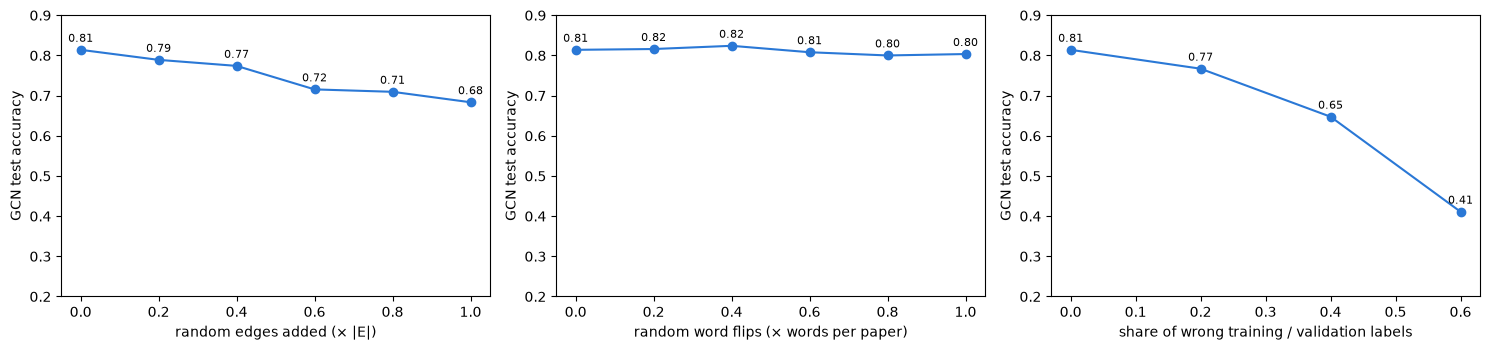

In [32]:
def random_attack(A, budget, seed=0):
    """Insert `budget` random edges."""
    g = torch.Generator().manual_seed(seed)
    M, added = A.clone(), 0
    while added < budget:
        u_, v_ = torch.randint(A.size(0), (2, 2 * budget), generator=g).tolist()
        for a_, b_ in zip(u_, v_):
            if a_ != b_ and M[a_, b_] == 0:
                M[a_, b_] = M[b_, a_] = 1.0; added += 1
                if added == budget:
                    break
    return M

def uniform_label_noise(labels, idx, rate, num_classes, seed=0):
    """Replace the labels of a `rate` share of the nodes idx by a different, uniformly random class."""
    g = torch.Generator().manual_seed(seed)
    out = labels.clone()
    flip = idx[torch.randperm(idx.numel(), generator=g)[:int(round(rate * idx.numel()))].to(idx.device)]
    out[flip] = (labels[flip] + torch.randint(1, num_classes, (flip.numel(),), generator=g).to(labels.device)) % num_classes
    return out

NOISE = {}
rates = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
NOISE['edges'] = [np.mean([gcn_on(random_attack(Ac, int(r * Ec), seed=s), seed=s)[0] for s in range(2)]) for r in rates]
g_ = torch.Generator().manual_seed(0)
def flip_features(rate):
    mask = torch.rand(Xb.shape, generator=g_).to(device) < rate * Xb.mean()          # rate · (number of words) random flips
    Xn = (Xb + mask.float()) % 2
    return Xn / Xn.sum(1, keepdim=True).clamp(min=1)
NOISE['features'] = [np.mean([gcn_on(Ac, X=flip_features(r), seed=s)[0] for s in range(2)]) for r in rates]
lab_rates = [0.0, 0.2, 0.4, 0.6]
NOISE['labels'] = [np.mean([gcn_on(Ac, labels=uniform_label_noise(yc, torch.cat([idx_train, idx_val]), r, Cc, seed=s), seed=s)[0]
                            for s in range(2)]) for r in lab_rates]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (key, xs, xl) in zip(axes, [('edges', rates, 'random edges added (× |E|)'),
                                    ('features', rates, 'random word flips (× words per paper)'),
                                    ('labels', lab_rates, 'share of wrong training / validation labels')]):
    ax.plot(xs, NOISE[key], marker='o', color=COLORS['GCN'])
    ax.set(xlabel=xl, ylabel='GCN test accuracy', ylim=(0.2, 0.9))
    for xv, yv in zip(xs, NOISE[key]):
        ax.text(xv, yv + 0.02, f'{yv:.2f}', ha='center', fontsize=8)
plt.tight_layout(); plt.show()

# 12. Adversarial attacks

An attacker chooses the perturbation that hurts most within a budget $\mathcal B$: $\max_{(\Delta A,\Delta X)\in\mathcal B}\mathcal L_{attack}(f_\theta(A+\Delta A, X+\Delta X), Y)$. Attacks differ by when they act: evasion attacks perturb the graph of an already trained model, poisoning attacks perturb the graph before training. They also differ by their target: targeted attacks aim at one node (direct: edges incident to the target; influence: edges nearby), non-targeted attacks lower the overall accuracy.

## 12.1. A targeted direct attack (in the spirit of Nettack)

For a target $t$ with label $y_t$, we greedily flip edges $(t, u)$ to decrease the classification margin $z_{t,y_t} - \max_{c\ne y_t} z_{t,c}$. Every step takes the flip with the most negative first-order change, $\frac{\partial\,\text{margin}}{\partial A_{tu}}\,(1 - 2A_{tu})$, computed by back-propagation through the dense adjacency matrix. The budget is $d_t + 2$ flips, as in the Nettack paper, and so is the choice of the 40 targets: among correctly classified test nodes, the 10 with the largest margin, the 10 with the smallest margin and 20 random ones. The random baseline links the target to $d_t+2$ random nodes.

In [33]:
def margin(out, labels):
    """z_y - max_{c != y} z_c (negative = misclassified)."""
    true = out.gather(-1, labels.unsqueeze(-1)).squeeze(-1)
    return true - out.scatter(-1, labels.unsqueeze(-1), -float('inf')).max(-1).values

def targeted_attack(model, X, A, target, label, budget, mode='gradient', seed=0):
    M = A.clone()
    g = torch.Generator().manual_seed(seed)
    for _ in range(budget):
        if mode == 'random':
            u_ = int(torch.randint(A.size(0), (1,), generator=g))
            while u_ == target or M[target, u_] > 0:
                u_ = int(torch.randint(A.size(0), (1,), generator=g))
        else:
            P = M.clone().requires_grad_(True)
            out = model(X, normalize_adj((P + P.t()) / 2))[target]
            G = torch.autograd.grad(margin(out, label), P)[0]
            with torch.no_grad():
                # ★ KEY: first-order change of the margin when flipping A_tu (adding if absent, removing if present).
                score = (G[target] + G[:, target]) * (1 - 2 * M[target])
                score[target] = float('inf')
                score[(M[target] > 0) & (M.sum(1) == 1)] = float('inf')        # never disconnect a neighbour
                u_ = int(score.argmin())
        M[target, u_] = M[u_, target] = 1 - M[target, u_]
    return M

with torch.no_grad():
    marg = margin(gcn_clean(Xc, A_hat_c), yc)
correct = pred_clean == yc
cand = idx_test[correct[idx_test]]
cand = cand[marg[cand].argsort()]
rest = cand[10:-10]
targets = torch.cat([cand[-10:], cand[:10], rest[torch.randperm(rest.numel(), generator=torch.Generator().manual_seed(0))[:20].to(device)]])
budgets = (Ac[targets].sum(1) + 2).long().tolist()

TARGETED = {}
t0 = time.time()
for mode in ['random', 'gradient']:
    graphs_t = [targeted_attack(gcn_clean, Xc, Ac, int(t), yc[t], b, mode=mode, seed=i) for i, (t, b) in enumerate(zip(targets, budgets))]
    with torch.no_grad():
        miss = [gcn_clean(Xc, normalize_adj(M))[t].argmax().item() != yc[t].item() for M, t in zip(graphs_t, targets)]
    TARGETED[mode] = graphs_t
    print(f'{mode:<8} direct attack, evasion: {np.mean(miss):.0%} of the 40 targets misclassified '
          f'(mean budget {np.mean(budgets):.1f} flips) | {time.time() - t0:.0f}s')
# Poisoning: apply the flips of all 40 targets at once and retrain the GCN
A_targeted = Ac.clone()
for M in TARGETED['gradient']:
    A_targeted = torch.where(M != Ac, M, A_targeted)
flips = (A_targeted != Ac).sum().item() // 2
_, pred_t, _ = gcn_on(A_targeted)
print(f'gradient attack, poisoning ({flips} flips for the 40 targets, GCN retrained): {(pred_t[targets] != yc[targets]).float().mean():.0%} misclassified')

random   direct attack, evasion: 22% of the 40 targets misclassified (mean budget 6.5 flips) | 0s
gradient direct attack, evasion: 92% of the 40 targets misclassified (mean budget 6.5 flips) | 2s
gradient attack, poisoning (259 flips for the 40 targets, GCN retrained): 68% misclassified


## 12.2. Global poisoning attacks: DICE and Metattack

* DICE (delete internally, connect externally): a heuristic that knows the labels. Half of the budget removes random edges inside a class, the other half adds random edges between classes.
* Metattack treats the graph as a hyper-parameter of training and follows the meta-gradient: the gradient of the attack loss after training, $\nabla_A\,\mathcal L_{atk}\big(f_{\theta^*(A)}\big)$, where $\theta^*(A)$ is obtained by 100 steps of SGD with momentum on a linearised 2-layer GCN $\hat A^2XW$ and back-propagation goes through all 100 steps. The Meta-Self variant uses as attack loss the cross-entropy on the unlabelled nodes with the predictions of a GCN trained on the clean graph as self-training labels. Each step flips the entry with the largest score $\nabla_{A_{uv}}\mathcal L_{atk}\cdot(1 - 2A_{uv})$ and never disconnects a node.

The budgets are 5% and 10% of the edges (263 and 527 flips).

In [34]:
def dice_attack(A, labels, budget, seed=0):
    g = torch.Generator().manual_seed(seed)
    M = A.clone()
    iu = torch.triu(A, 1).nonzero()
    inside = iu[labels[iu[:, 0]] == labels[iu[:, 1]]]
    drop = inside[torch.randperm(inside.size(0), generator=g)[:budget // 2].to(A.device)]
    M[drop[:, 0], drop[:, 1]] = M[drop[:, 1], drop[:, 0]] = 0.0
    added = 0
    while added < budget - budget // 2:
        u_, v_ = torch.randint(A.size(0), (2, 4 * budget), generator=g).to(A.device)
        ok = (u_ != v_) & (labels[u_] != labels[v_]) & (M[u_, v_] == 0)
        for a_, b_ in zip(u_[ok].tolist(), v_[ok].tolist()):
            if M[a_, b_] == 0:
                M[a_, b_] = M[b_, a_] = 1.0; added += 1
                if added == budget - budget // 2:
                    break
    return M

def metattack(A, X, labels, idx_train, idx_unlabeled, self_labels, budget, hidden=16, train_iters=100, lr=0.1, momentum=0.9):
    """Metattack (Meta-Self): `budget` greedy flips chosen by the meta-gradient of the self-training loss."""
    N, C = A.size(0), int(labels.max()) + 1
    M = A.clone()
    for step in range(budget):
        P = M.clone().requires_grad_(True)
        A_hat = normalize_adj((P + P.t()) / 2)
        AX = A_hat @ X
        w1 = ((torch.rand(X.size(1), hidden, device=device) * 2 - 1) * math.sqrt(6 / (X.size(1) + hidden))).requires_grad_(True)
        w2 = ((torch.rand(hidden, C, device=device) * 2 - 1) * math.sqrt(6 / (hidden + C))).requires_grad_(True)
        v1, v2 = torch.zeros_like(w1), torch.zeros_like(w2)
        for _ in range(train_iters):          # inner training, kept in the autograd graph (create_graph=True)
            loss = F.cross_entropy((A_hat @ (AX @ w1) @ w2)[idx_train], labels[idx_train])
            g1, g2 = torch.autograd.grad(loss, [w1, w2], create_graph=True)
            v1, v2 = momentum * v1 + g1, momentum * v2 + g2
            w1, w2 = w1 - lr * v1, w2 - lr * v2
        attack_loss = F.cross_entropy((A_hat @ (AX @ w1) @ w2)[idx_unlabeled], self_labels[idx_unlabeled])
        # ★ KEY: the meta-gradient: how the loss AFTER training changes with every entry of the adjacency matrix.
        G = torch.autograd.grad(attack_loss, P)[0]
        with torch.no_grad():
            score = (G + G.t()) * (1 - 2 * M)
            deg = M.sum(1)
            score[(M > 0) & ((deg == 1)[:, None] | (deg == 1)[None, :])] = -float('inf')    # never disconnect a node
            score = torch.triu(score, diagonal=1) + torch.tril(torch.full_like(score, -float('inf')))
            k = int(score.view(-1).argmax())
            a_, b_ = k // N, k % N
            M[a_, b_] = M[b_, a_] = 1 - M[a_, b_]
    return M

idx_unlabeled = (~split[0]).nonzero().view(-1)
self_labels = torch.where(split[0], yc, pred_clean)               # Meta-Self: true labels on V_L, GCN predictions elsewhere
ATTACKED = {'clean': Ac, 'random 10%': random_attack(Ac, int(0.1 * Ec)), 'DICE 10%': dice_attack(Ac, yc, int(0.1 * Ec))}
for rate in [0.05, 0.10]:
    t0 = time.time()
    ATTACKED[f'Metattack {int(rate * 100)}%'] = metattack(Ac, Xc, yc, idx_train, idx_unlabeled, self_labels, int(rate * Ec))
    print(f'Metattack {int(rate * 100)}% ({int(rate * Ec)} flips): {time.time() - t0:.0f}s')

Xn = F.normalize(Xb, dim=1)
clean_e = torch.triu(Ac, 1).nonzero()
print(f"\n{'graph':<14}{'added':>7}{'removed':>9}{'added: other class':>20}{'added: touches V_L':>20}{'added: feature cos':>20}")
for name, M in ATTACKED.items():
    add = torch.triu((M > 0) & (Ac == 0), 1).nonzero(); rem = int(torch.triu((M == 0) & (Ac > 0), 1).sum())
    if add.numel() == 0:
        print(f"{name:<14}{0:>7}{rem:>9}{'-':>20}{'-':>20}{(Xn[clean_e[:, 0]] * Xn[clean_e[:, 1]]).sum(1).mean():>20.3f}  (clean edges)")
        continue
    other = (yc[add[:, 0]] != yc[add[:, 1]]).float().mean()
    touch = (split[0][add[:, 0]] | split[0][add[:, 1]]).float().mean()
    cos = (Xn[add[:, 0]] * Xn[add[:, 1]]).sum(1).mean()
    print(f'{name:<14}{add.size(0):>7}{rem:>9}{other:>20.2f}{touch:>20.2f}{cos:>20.3f}')

Metattack 5% (263 flips): 111s
Metattack 10% (527 flips): 220s

graph           added  removed  added: other class  added: touches V_L  added: feature cos
clean               0        0                   -                   -               0.168  (clean edges)
random 10%        527        0                0.83                0.09               0.054
DICE 10%          264      263                1.00                0.11               0.049
Metattack 5%      261        2                1.00                0.94               0.027
Metattack 10%     503       22                0.99                0.94               0.030


In [35]:
ROBUST = {}
for name, M in ATTACKED.items():
    ROBUST.setdefault('GCN', {})[name] = np.mean([gcn_on(M, seed=s)[0] for s in range(2)])
print('GCN test accuracy (poisoning, 2 seeds): ' + ' | '.join(f'{k} {v:.3f}' for k, v in ROBUST['GCN'].items()))

GCN test accuracy (poisoning, 2 seeds): clean 0.814 | random 10% 0.806 | DICE 10% 0.795 | Metattack 5% 0.732 | Metattack 10% 0.608


# 13. Defences

## 13.1. GNNGuard: neighbour importance

Attacks insert edges between dissimilar nodes. GNNGuard re-weights every edge at every layer $k$ from the similarity of its endpoints:
* $s_{uv} = \cos(h_u^{(k)}, h_v^{(k)})$; edges with $s_{uv} < 0.1$ are pruned;
* the remaining weights are normalised over the neighbourhood, $\alpha_{uv} = s_{uv}/\sum_{w\in\mathcal N(v)} s_{wv}$, and the self-loop gets $1/(1 + |\text{kept neighbours}|)$;
* layer-wise memory: $\omega^{(k)} = \beta\,\omega^{(k-1)} + (1-\beta)\,\alpha^{(k)}$ smooths the weights across layers. The official code turns it off ($\beta = 0$), and we follow it.

The message passing is then $h_v^{(k+1)} = \sigma\big(\sum_{u\in\mathcal N(v)\cup\{v\}}\omega_{uv}^{(k)}W^{(k)}h_u^{(k)}\big)$. GNNGuard assumes homophily: on heterophilous graphs it measures structural similarity instead.

In [36]:
class GNNGuard(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, dropout=0.5, threshold=0.1, beta=0.0):
        super().__init__()
        self.lin1, self.lin2 = nn.Linear(in_dim, hidden), nn.Linear(hidden, out_dim)
        self.dropout, self.threshold, self.beta = dropout, threshold, beta

    def importance(self, h, edge_index):
        src, dst = edge_index
        sim = F.cosine_similarity(h[src], h[dst], dim=-1)
        # ★ KEY: prune the edges between dissimilar nodes, normalise the others over every neighbourhood.
        sim = torch.where(sim < self.threshold, torch.zeros_like(sim), sim)
        w = sim / scatter_sum(sim, dst, h.size(0)).clamp(min=1e-12)[dst]
        self_w = 1.0 / (1.0 + degree(dst[w > 0], h.size(0)))
        return w, self_w

    def propagate(self, h, edge_index, w, self_w):
        return scatter_sum(w[:, None] * h[edge_index[0]], edge_index[1], h.size(0)) + self_w[:, None] * h

    def forward(self, X, edge_index):
        w1, s1 = self.importance(X, edge_index)
        h = F.relu(self.propagate(self.lin1(F.dropout(X, self.dropout, self.training)), edge_index, w1, s1))
        w2, s2 = self.importance(h, edge_index)
        w2, s2 = self.beta * w1 + (1 - self.beta) * w2, self.beta * s1 + (1 - self.beta) * s2     # layer-wise memory
        self.kept = ((w1 > 0).float().mean().item(), (w2 > 0).float().mean().item())
        return self.propagate(self.lin2(F.dropout(h, self.dropout, self.training)), edge_index, w2, s2)

for name, M in ATTACKED.items():
    ei_m = M.nonzero().t()
    accs = []
    for s in range(2):
        set_seed(s)
        guard = GNNGuard(Xc.size(1), 16, Cc).to(device)
        accs.append(train_node_model(guard, lambda: guard(Xc, ei_m), yc)[0])
    ROBUST.setdefault('GNNGuard', {})[name] = np.mean(accs)
    add = (M > 0) & (Ac == 0)
    with torch.no_grad():
        w1, _ = guard.importance(Xc, ei_m)
    kept_add = (w1[add[ei_m[0], ei_m[1]]] > 0).float().mean().item() if add.any() else float('nan')
    kept_clean = (w1[Ac[ei_m[0], ei_m[1]] > 0] > 0).float().mean().item()
    print(f'{name:<14}: GNNGuard {ROBUST["GNNGuard"][name]:.3f} (GCN {ROBUST["GCN"][name]:.3f}) | layer 1 keeps '
          f'{kept_clean:.0%} of the clean edges and {kept_add:.0%} of the inserted ones')

clean         : GNNGuard 0.806 (GCN 0.814) | layer 1 keeps 68% of the clean edges and nan% of the inserted ones
random 10%    : GNNGuard 0.795 (GCN 0.806) | layer 1 keeps 68% of the clean edges and 21% of the inserted ones
DICE 10%      : GNNGuard 0.780 (GCN 0.795) | layer 1 keeps 68% of the clean edges and 17% of the inserted ones
Metattack 5%  : GNNGuard 0.750 (GCN 0.732) | layer 1 keeps 68% of the clean edges and 10% of the inserted ones
Metattack 10% : GNNGuard 0.680 (GCN 0.608) | layer 1 keeps 68% of the clean edges and 12% of the inserted ones


## 13.2. Pro-GNN: learning a clean structure

Pro-GNN learns a new adjacency matrix $S$ together with the GCN, using properties that attacks violate: clean graphs are sparse, low-rank and feature-smooth:

$$\min_{W,\,S\in[0,1]^{N\times N},\,S=S^\top}\ \mathcal L_{GNN}(W, S) \;+\; \alpha\|S\|_1 \;+\; \beta\|S\|_* \;+\; \|S - A\|_F^2 \;+\; \lambda\,\mathrm{tr}(X^\top L_S X),$$

with $\mathrm{tr}(X^\top L_S X) = \frac12\sum_{ij}S_{ij}\|x_i - x_j\|^2$ (the Pro-GNN code uses the normalised Laplacian). The alternating optimisation repeats: (1) two Adam steps on $W$ with $S$ fixed; (2) one SGD step on $S$ for the differentiable terms, then the proximal operators of the non-differentiable norms: singular value soft-thresholding for $\|S\|_*$, entry-wise soft-thresholding for $\|S\|_1$, then projection onto $[0, 1]$ and symmetrisation.

Every step needs an SVD of a $2708\times2708$ matrix. We train 300 epoches, on the clean graph and on Metattack 10% only. Hyper-parameters: $\alpha = 5\cdot10^{-4}$, $\beta = 1.5$, $\gamma = 1$ (the weight of $\mathcal L_{GNN}$), step size $0.01$ for $S$, and $\lambda = 0.03$ on the binary features.

In [37]:
def prognn(X, A, labels, epochs=300, lr=0.01, lr_adj=0.01, alpha=5e-4, beta=1.5, gamma=1.0, lam=0.03, X_smooth=Xb, seed=0):
    set_seed(seed)
    tr, va, te = split
    N = A.size(0)
    model = DenseGCN(X.size(1), 16, int(labels.max()) + 1).to(device)
    opt_w = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    S = nn.Parameter(A.clone())
    opt_s = torch.optim.SGD([S], lr=lr_adj, momentum=0.9)
    best, best_state, best_S = -1, None, None
    for epoch in range(epochs):
        A_hat = normalize_adj(S.detach())
        for _ in range(2):                                         # step 1: update W with S fixed
            model.train(); opt_w.zero_grad()
            F.cross_entropy(model(X, A_hat)[tr], labels[tr]).backward(); opt_w.step()
        model.eval()                                               # step 2: update S with W fixed
        opt_s.zero_grad()
        Ssym = (S + S.t()) / 2
        d = Ssym.sum(1) + 1e-3
        L = torch.eye(N, device=device) - Ssym / torch.sqrt(d[:, None] * d[None, :])        # normalised Laplacian of S
        loss = torch.norm(S - A) ** 2 + gamma * F.cross_entropy(model(X, normalize_adj(Ssym))[tr], labels[tr]) \
               + lam * (X_smooth * (L @ X_smooth)).sum()
        loss.backward(); opt_s.step()
        with torch.no_grad():
            # ★ KEY: proximal operators: soft-threshold the singular values (‖S‖_*) and the entries (‖S‖_1).
            U, sv, Vh = torch.linalg.svd(S)
            S.copy_(U @ torch.diag(torch.clamp(sv - lr_adj * beta, min=0)) @ Vh)
            S.copy_(torch.sign(S) * torch.clamp(S.abs() - lr_adj * alpha, min=0))
            S.clamp_(0, 1)
            S.copy_((S + S.t()) / 2)
            va_acc = (model(X, normalize_adj(S))[va].argmax(1) == labels[va]).float().mean().item()
        if va_acc > best:
            best, best_state, best_S = va_acc, copy.deepcopy(model.state_dict()), S.detach().clone()
    model.load_state_dict(best_state)
    with torch.no_grad():
        pred = model(X, normalize_adj(best_S)).argmax(1)
    return (pred[te] == labels[te]).float().mean().item(), best_S

for name in ['clean', 'Metattack 10%']:
    M = ATTACKED[name]
    t0 = time.time()
    acc, S_learned = prognn(Xc, M, yc)
    ROBUST.setdefault('Pro-GNN', {})[name] = acc
    add = (M > 0) & (Ac == 0)
    msg = f' | mean S_uv on inserted edges {S_learned[add].mean():.3f} vs. clean edges {S_learned[Ac > 0].mean():.3f}' if add.any() else ''
    print(f'{name:<14}: Pro-GNN {acc:.3f} (GCN {ROBUST["GCN"][name]:.3f}) | {time.time() - t0:.0f}s{msg}')

clean         : Pro-GNN 0.828 (GCN 0.814) | 220s
Metattack 10% : Pro-GNN 0.626 (GCN 0.608) | 216s | mean S_uv on inserted edges 0.971 vs. clean edges 0.971


## 13.3. GRAND: random propagation + consistency

GRAND does not touch the graph; it makes the predictions insensitive to which nodes and edges are present:
1. DropNode: $\tilde X = \frac{1}{1-\delta}\,\epsilon\odot X$ with $\epsilon_i\sim\mathrm{Bern}(1-\delta)$ per node (whole rows are dropped), $\delta = 0.5$.
2. Mixed-order propagation: $\bar X = \frac{1}{K+1}\sum_{k=0}^{K}\hat A^k\tilde X$ with $K = 8$, then an MLP.
3. Consistency: $S = 4$ augmentations give $P^{(1)},\dots,P^{(S)}$. Their mean is sharpened, $P'_{ic}\propto\bar P_{ic}^{1/T}$ with $T = 0.5$, and every $P^{(s)}$ is pulled towards it on **all** nodes. The loss is $\mathcal L = \mathcal L_{sup} + \lambda\mathcal L_{con}$ with $\lambda = 1$.

The GRAND uses the squared distance $\frac1n\sum_i\frac1S\sum_s\|P'_i - P_i^{(s)}\|^2$. Unlike the KL divergence, it is bounded, which matters under attack. Hyper-parameters are those of the GRAND paper for Cora (hidden 32, input / hidden dropout 0.5, Adam 0.01, weight decay $5\cdot10^{-4}$, patience 200).

In [38]:
class GRAND(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, K=8, drop_node=0.5, input_dropout=0.5, hidden_dropout=0.5):
        super().__init__()
        self.lin1, self.lin2 = nn.Linear(in_dim, hidden), nn.Linear(hidden, out_dim)
        self.K, self.drop_node, self.in_drop, self.hid_drop = K, drop_node, input_dropout, hidden_dropout

    def forward(self, X, norm_edges):
        src, dst, w = norm_edges
        if self.training:
            # ★ KEY: DropNode: drop whole feature rows with probability δ and rescale by 1 / (1 - δ).
            keep = torch.bernoulli(torch.full((X.size(0), 1), 1 - self.drop_node, device=X.device))
            X = X * keep / (1 - self.drop_node)
        out, h = X, X
        for _ in range(self.K):                                   # mixed-order propagation (1/(K+1)) Σ_k Â^k X̃
            h = scatter_sum(w[:, None] * h[src], dst, X.size(0))
            out = out + h
        H = F.dropout(out / (self.K + 1), self.in_drop, self.training)
        return self.lin2(F.dropout(F.relu(self.lin1(H)), self.hid_drop, self.training))

def train_grand(model, X, norm_edges, labels, S=4, T=0.5, lam=1.0, epochs=1000, lr=0.01, wd=5e-4, patience=200, consistency='l2'):
    tr, va, te = split
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    best, bad, best_state = -1, 0, None
    for epoch in range(epochs):
        model.train(); opt.zero_grad()
        logps = [F.log_softmax(model(X, norm_edges), -1) for _ in range(S)]            # S random augmentations
        loss_sup = sum(F.nll_loss(lp[tr], labels[tr]) for lp in logps) / S
        P_bar = torch.stack([lp.exp() for lp in logps]).mean(0)
        sharp = P_bar.pow(1 / T)
        sharp = (sharp / sharp.sum(1, keepdim=True)).detach()                           # sharpened guess P'
        if consistency == 'l2':
            loss_con = sum(((lp.exp() - sharp) ** 2).sum(1).mean() for lp in logps) / S
        else:                                                                            # D_KL(P' || P^(s))
            loss_con = sum(F.kl_div(lp, sharp, reduction='batchmean') for lp in logps) / S
        (loss_sup + lam * loss_con).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            va_acc = (model(X, norm_edges)[va].argmax(1) == labels[va]).float().mean().item()
        if va_acc > best:
            best, bad, best_state = va_acc, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        pred = model(X, norm_edges).argmax(1)
    return (pred[te] == yc[te]).float().mean().item(), pred

t0 = time.time()
for name, M in ATTACKED.items():
    ne = gcn_norm(M.nonzero().t(), Nc)
    accs = []
    for s in range(2):
        set_seed(s)
        accs.append(train_grand(GRAND(Xc.size(1), 32, Cc).to(device), Xc, ne, yc)[0])
    ROBUST.setdefault('GRAND', {})[name] = np.mean(accs)
print(f'GRAND trained on {len(ATTACKED)} graphs x 2 seeds in {time.time() - t0:.0f}s')

print(f"\n{'graph':<16}" + ''.join(f'{m:>10}' for m in ROBUST))
for name in ATTACKED:
    print(f'{name:<16}' + ''.join(f'{ROBUST[m][name]:>10.3f}' if name in ROBUST[m] else f'{"-":>10}' for m in ROBUST))

GRAND trained on 5 graphs x 2 seeds in 143s

graph                  GCN  GNNGuard   Pro-GNN     GRAND
clean                0.814     0.806     0.828     0.845
random 10%           0.806     0.795         -     0.828
DICE 10%             0.795     0.780         -     0.826
Metattack 5%         0.732     0.750         -     0.811
Metattack 10%        0.608     0.680     0.626     0.714


In [39]:
# The 40 targets of Section 12.1 under the poisoning attack: GCN vs. the defences
miss = {}
_, p_, _ = gcn_on(A_targeted); miss['GCN'] = p_
ei_t = A_targeted.nonzero().t()
set_seed(0); guard = GNNGuard(Xc.size(1), 16, Cc).to(device); miss['GNNGuard'] = train_node_model(guard, lambda: guard(Xc, ei_t), yc)[1]
set_seed(0); miss['GRAND'] = train_grand(GRAND(Xc.size(1), 32, Cc).to(device), Xc, gcn_norm(ei_t, Nc), yc)[1]
print('Targeted poisoning attack, share of the 40 targets misclassified: ' +
      ' | '.join(f'{k} {(p[targets] != yc[targets]).float().mean():.0%}' for k, p in miss.items()))

Targeted poisoning attack, share of the 40 targets misclassified: GCN 68% | GNNGuard 75% | GRAND 75%


# 14. NRGNN: learning with noisy labels

A wrong training label pulls the shared weights towards the wrong class, and with few labels every label matters. NRGNN has three parts trained jointly:
1. Edge predictor: a GCN encoder gives normalised node embeddings $z$; the weight of a pair is $w_{uv} = \mathrm{ReLU}(z_u^\top z_v)$, set to 0 below $t = 0.1$, and the encoder is trained to reconstruct the observed edges (weight 1) against random pairs (weight 0). Every node is linked to its $n_p$ most similar labelled nodes (cosine of the features), with predicted weights: this densifies the graph around the labels.
2. Pseudo-label miner: a GCN on the densified graph; unlabelled nodes predicted with confidence $> 0.8$ get a pseudo label.
3. Classifier: a GCN on the densified graph, trained on the noisy labels and on the pseudo labels (soft labels of the miner). Total loss: $\mathcal L_{GCN} + \mathcal L_{miner} + 0.03\,\mathcal L_{rec} + \mathcal L_{pseudo}$.

Two changes to the NRGNN code: the edge predictor is first trained alone for 200 steps (otherwise the untrained predictor links every node to all its candidates with weight ≈ 1), and we do not add the code's extra links between all unlabelled and all pseudo-labelled nodes, which made training unstable in our tests. We use $n_p = 5$ and a learning rate of 0.01 for every model.

In [40]:
class EdgeGCN(nn.Module):
    """2-layer GCN on a weighted edge list."""
    def __init__(self, in_dim, hidden, out_dim, dropout=0.5):
        super().__init__()
        self.lin1, self.lin2, self.dropout = nn.Linear(in_dim, hidden), nn.Linear(hidden, out_dim), dropout
    def forward(self, X, edge_index, edge_weight=None):
        src, dst, w = gcn_norm(edge_index, X.size(0), edge_weight)
        h = F.relu(scatter_sum(w[:, None] * self.lin1(F.dropout(X, self.dropout, self.training))[src], dst, X.size(0)))
        return scatter_sum(w[:, None] * self.lin2(F.dropout(h, self.dropout, self.training))[src], dst, X.size(0))

def nrgnn(X, edge_index, y_noisy, idx_train, idx_val, idx_unlabel, epochs=200, lr=0.01, hidden=16, edge_hidden=64, n_p=5,
          t_small=0.1, p_u=0.8, alpha=0.03, beta=1.0, n_neg=50, warmup=200, seed=0):
    set_seed(seed)
    N, C = X.size(0), int(y_noisy.max()) + 1
    src, dst = edge_index
    # candidate edges: every node <-> its n_p most similar labelled nodes (cosine of the features)
    Xn_ = F.normalize(X, dim=1)
    top = (Xn_ @ Xn_[idx_train].t()).topk(n_p, dim=1).indices
    cand = torch.stack([torch.arange(N, device=device).repeat_interleave(n_p), idx_train[top.reshape(-1)]])
    cand = cand[:, (cand[0] != cand[1]) & ~torch.isin(cand[0] * N + cand[1], src * N + dst)]
    cand = torch.unique(torch.cat([cand, cand.flip(0)], 1), dim=1)
    estimator = EdgeGCN(X.size(1), edge_hidden, edge_hidden, dropout=0.0).to(device)
    miner, model = EdgeGCN(X.size(1), hidden, C).to(device), EdgeGCN(X.size(1), hidden, C).to(device)

    def embed():
        return F.normalize(estimator(X, edge_index), dim=1)
    def rec_loss(Z):
        neg = torch.randint(N, (2, n_neg * N), device=device)
        return ((((Z[src] * Z[dst]).sum(1) - 1) ** 2).sum() + ((Z[neg[0]] * Z[neg[1]]).sum(1) ** 2).sum()) / (src.numel() + neg.size(1))
    def weights(Z):
        w = F.relu((Z[cand[0]] * Z[cand[1]]).sum(1))
        return torch.where(w < t_small, torch.zeros_like(w), w)

    opt_e = torch.optim.Adam(estimator.parameters(), lr=0.01)
    for _ in range(warmup):                                       # warm-up of the edge predictor
        opt_e.zero_grad(); rec_loss(embed()).backward(); opt_e.step()
    params = list(estimator.parameters()) + list(miner.parameters()) + list(model.parameters())
    opt = torch.optim.Adam(params, lr=lr, weight_decay=5e-4)
    ei_all = torch.cat([edge_index, cand], 1)
    ones = torch.ones(edge_index.size(1), device=device)
    soft, idx_add, best_miner, best_val, best_pred = None, idx_unlabel[:0], -1, -1, None
    for epoch in range(epochs):
        estimator.train(); miner.train(); model.train(); opt.zero_grad()
        Z = embed()
        # ★ KEY: the densified graph: observed edges (weight 1) + links to similar labelled nodes (predicted weights).
        w_all = torch.cat([ones, weights(Z)])
        out_miner, out = miner(X, ei_all, w_all), model(X, ei_all, w_all)
        loss = F.cross_entropy(out[idx_train], y_noisy[idx_train]) + F.cross_entropy(out_miner[idx_train], y_noisy[idx_train]) \
               + alpha * rec_loss(Z)
        if idx_add.numel():
            loss = loss + beta * -(soft[idx_add] * F.log_softmax(out[idx_add], 1)).sum(1).mean()   # pseudo labels
        loss.backward(); opt.step()
        estimator.eval(); miner.eval(); model.eval()
        with torch.no_grad():
            w_all = torch.cat([ones, weights(embed())])
            p_miner = F.softmax(miner(X, ei_all, w_all), 1)
            acc_miner = (p_miner[idx_val].argmax(1) == y_noisy[idx_val]).float().mean().item()
            if acc_miner > best_miner:                            # pseudo labels from the best miner so far
                best_miner, soft = acc_miner, p_miner
                idx_add = idx_unlabel[p_miner[idx_unlabel].max(1).values > p_u]
            out = model(X, ei_all, w_all)
            acc_val = (out[idx_val].argmax(1) == y_noisy[idx_val]).float().mean().item()
            if acc_val > best_val:
                best_val, best_pred = acc_val, out.argmax(1)
    return best_pred, cand, idx_add

ei_c = cora.edge_index.to(device)
idx_unl = torch.tensor(sorted(set(range(Nc)) - set(idx_train.tolist()) - set(idx_val.tolist())), device=device)
LABEL_NOISE = {}
for rate in [0.0, 0.2, 0.4]:
    y_noisy = uniform_label_noise(yc, torch.cat([idx_train, idx_val]), rate, Cc, seed=0)
    gcn_accs, nr_accs = [], []
    for s in range(3):
        set_seed(s)
        m = EdgeGCN(Xc.size(1), 16, Cc).to(device)
        gcn_accs.append(train_node_model(m, lambda: m(Xc, ei_c), y_noisy, y_test=yc)[0])
        pred_nr, cand, idx_add = nrgnn(Xc, ei_c, y_noisy, idx_train, idx_val, idx_unl, seed=s)
        nr_accs.append((pred_nr[idx_test] == yc[idx_test]).float().mean().item())
    LABEL_NOISE[rate] = (gcn_accs, nr_accs)
    print(f'label noise {rate:.0%} ({int((y_noisy[idx_train] != yc[idx_train]).sum())} of 140 training labels wrong): '
          f'GCN {np.mean(gcn_accs):.3f} ± {np.std(gcn_accs):.3f} | NRGNN {np.mean(nr_accs):.3f} ± {np.std(nr_accs):.3f} '
          f'| pseudo labels {idx_add.numel()} (correct: {(pred_nr[idx_add] == yc[idx_add]).float().mean():.0%})')
same = (yc[cand[0]] == yc[cand[1]]).float().mean().item()
print(f'\nCandidate links: {cand.size(1) // 2} | they join two nodes of the same class in {same:.0%} of the cases '
      f'(observed edges: {(yc[ei_c[0]] == yc[ei_c[1]]).float().mean():.0%})')

label noise 0% (0 of 140 training labels wrong): GCN 0.815 ± 0.007 | NRGNN 0.795 ± 0.014 | pseudo labels 106 (correct: 100%)
label noise 20% (23 of 140 training labels wrong): GCN 0.770 ± 0.003 | NRGNN 0.737 ± 0.007 | pseudo labels 102 (correct: 99%)
label noise 40% (55 of 140 training labels wrong): GCN 0.631 ± 0.010 | NRGNN 0.682 ± 0.019 | pseudo labels 26 (correct: 81%)

Candidate links: 13018 | they join two nodes of the same class in 36% of the cases (observed edges: 81%)


# 15. Certified robustness

The defences above are empirical: they resist the attacks we tried. A certificate proves that $\hat y_v(G') = \hat y_v(G)$ for every $G'$ in the threat model $\mathcal B_B(G)$. With $c^* = \hat y_v(G)$, it suffices that the worst-case class margin stays positive:

$$\min_{G'\in\mathcal B_B(G)}\Big[z_{v,c^*}(G') - \max_{c\ne c^*}z_{v,c}(G')\Big] > 0 .$$

For a 2-layer GCN this minimum is hard: Zügner & Günnemann bound it with convex relaxations or branch-and-bound. For a linear GNN it can be computed exactly. SGC, $z = \hat A^2 X W + b$, is linear in the binary features $X$. Flipping word $d$ of paper $u$ changes the margin against class $c$ by

$$\delta_{ud} = (\hat A^2)_{vu}\,(1 - 2X_{ud})\,(W_{d,c^*} - W_{d,c}),$$

independently of the other flips. So the worst case under at most $Q$ flips is the margin plus the $Q$ most negative $\delta_{ud}$: the certificate is exact (the same flips are the optimal attack).

SGC (Â² X W) test accuracy: 0.798
certificates of 1000 test nodes for Q = 0..50 flips in 6s
Q =  0 flipped words: certified 1.000 | certified and correct (= accuracy under the optimal attack) 0.798
Q =  1 flipped words: certified 0.877 | certified and correct (= accuracy under the optimal attack) 0.738
Q =  2 flipped words: certified 0.797 | certified and correct (= accuracy under the optimal attack) 0.696
Q =  5 flipped words: certified 0.600 | certified and correct (= accuracy under the optimal attack) 0.553
Q = 10 flipped words: certified 0.352 | certified and correct (= accuracy under the optimal attack) 0.337
Q = 20 flipped words: certified 0.137 | certified and correct (= accuracy under the optimal attack) 0.134
Q = 50 flipped words: certified 0.005 | certified and correct (= accuracy under the optimal attack) 0.005


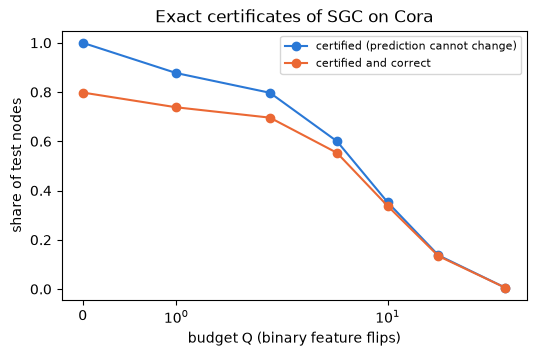

In [41]:
S2 = A_hat_c @ A_hat_c
SX = S2 @ Xb                                                    # SGC features Â² X (binary X)
set_seed(0)
sgc = nn.Linear(Xb.size(1), Cc).to(device)
acc_sgc, pred_sgc = train_node_model(sgc, lambda: sgc(SX), yc, lr=0.2, wd=5e-5, epochs=200)
print(f'SGC (Â² X W) test accuracy: {acc_sgc:.3f}')
W_, b_ = sgc.weight.detach().t(), sgc.bias.detach()

@torch.no_grad()
def worst_case_margins(nodes, Q_max):
    """[len(nodes), Q_max + 1]: exact worst-case margin of SGC under q = 0..Q_max binary feature flips."""
    Z = SX[nodes] @ W_ + b_
    c_star = Z.argmax(1)
    out = []
    for k, v_ in enumerate(nodes.tolist()):
        nz = (S2[v_] > 0).nonzero().view(-1)                    # only papers within 2 hops can change z_v
        coef, sign = S2[v_, nz], 1 - 2 * Xb[nz]
        dW = W_[:, c_star[k]][:, None] - W_                     # [features, classes]
        per_class = []
        for c in range(Cc):
            if c == c_star[k]:
                continue
            delta = (coef[:, None] * sign * dW[:, c][None, :]).reshape(-1)          # change of the margin per flip
            worst = torch.topk(torch.clamp(-delta, min=0), Q_max).values          # the Q_max most damaging flips
            # ★ KEY: worst margin after q flips = margin - (sum of the q largest damages): exact for a linear model.
            per_class.append(Z[k, c_star[k]] - Z[k, c] - torch.cat([torch.zeros(1, device=device), worst.cumsum(0)]))
        out.append(torch.stack(per_class).min(0).values)
    return torch.stack(out), c_star

t0 = time.time()
wm, c_star = worst_case_margins(idx_test, 50)
Qs = [0, 1, 2, 5, 10, 20, 50]
cert = [(wm[:, q] > 0).float().mean().item() for q in Qs]
cert_acc = [((wm[:, q] > 0) & (c_star == yc[idx_test])).float().mean().item() for q in Qs]
print(f'certificates of {len(idx_test)} test nodes for Q = 0..50 flips in {time.time() - t0:.0f}s')
for q, c, ca in zip(Qs, cert, cert_acc):
    print(f'Q = {q:>2} flipped words: certified {c:.3f} | certified and correct (= accuracy under the optimal attack) {ca:.3f}')
plt.figure(figsize=(6, 3.5))
plt.plot(Qs, cert, marker='o', label='certified (prediction cannot change)', color=COLORS['GCN'])
plt.plot(Qs, cert_acc, marker='o', label='certified and correct', color=COLORS['GNNGuard'])
plt.xscale('symlog'); plt.xlabel('budget Q (binary feature flips)'); plt.ylabel('share of test nodes'); plt.legend(fontsize=8)
plt.title('Exact certificates of SGC on Cora'); plt.show()